# Homework - 3

In this homework, you will learn:

* How to run and train a Diffusion Model
* How to generate high-resolution images
* How to evaluate a generative model performance

As in the previous homework, we expect you to create configurable code and put all the cells in the chronological order, so your solution can be run sequentially. Also, you must use [Comet](https://www.comet.com/site/) for tracking and provide a Comet Report together with the ipynb notebook in your submission. This time, you will also log image samples in the report.

LLM-generated code/analysis for tasks is strongly discouraged.

Penalties will be applied if these rules are not followed.

## Part 1: Understanding the inference pipeline

**Note:** Before starting the homework, we strongly encourage you to read the [DDPM](https://arxiv.org/abs/2006.11239) paper.



In this part, our primary goal is to understand the components of the diffusion pipeline and how they are connected with each other. To do so, we will start with the `diffusers` library. Our particular focus is on the [Stable Diffusion](https://arxiv.org/abs/2112.10752) model.

Stable Diffusion can be seen as an extension of [Denoising Diffusion Probabilistic Models (DDPM)](https://arxiv.org/abs/2006.11239), with the key distinction that the diffusion process is carried out in a *latent* space rather than directly on image pixels. This is enabled by a [Variational Autoencoder (VAE)](https://arxiv.org/abs/1312.6114), which first compresses an image into a lower-dimensional latent representation. The diffusion process is then applied to this latent, and the final denoised representation is decoded back into image space using the VAE decoder.

In more detail, let $x \in \mathbb{R}^{H \times W \times 3}$ be an image. A Variational Autoencoder (VAE) consists of an encoder $E$ and a decoder $D$:
$$
\mu(x), \sigma(x) = E(x), \qquad z_0 = \mu(x) + \sigma(x) \odot \epsilon, \epsilon \sim \mathcal{N}(0, 1) \qquad \hat{x} = D(z_0),
$$
where $z_0 \in \mathbb{R}^{h \times w \times c}$ is a lower-dimensional latent representation.

Instead of applying diffusion directly to $x$, a Latent Diffusion Model (LDM) performs the forward process in the latent space:
$$
q(z_t \mid z_{t-1}) = \mathcal{N}\big(z_t; \sqrt{1 - \beta_t}\, z_{t-1}, \beta_t I \big),
$$
which implies the closed form:
$$
q(z_t \mid z_0) = \mathcal{N}\big(z_t; \sqrt{\bar{\alpha}_t}\, z_0, (1 - \bar{\alpha}_t) I \big),
$$
where $\alpha_t = 1 - \beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$.

The model learns to reverse this process by predicting the noise $\epsilon$ using a neural network $\theta$:
$$
\epsilon_\theta(z_t, t).
$$
The reverse (denoising) step is then:
$$
p_\theta(z_{t-1} \mid z_t) = \mathcal{N}\big(z_{t-1}; \mu_\theta(z_t, t), \sigma_t^2 I \big),
$$
with
$$
\mu_\theta(z_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( z_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \, \epsilon_\theta(z_t, t) \right).
$$
After iteratively denoising to obtain $z_0$, the final image is reconstructed via the decoder:
$$
z_T \to z_0, \qquad \hat{x} = D(z_0).
$$

**Note:** this whole process can be made conditional by adding a condition $c$ as input for the model $\theta$, i.e., the predicted noise becomes $\epsilon_{\theta}(z_t, t, c)$. If, for example, vanilla unconditional diffusion just generates any images similar to the distribution of the training data, a conditional diffusion can generate images aligned with a text prompt.

Typically, a [UNet](https://arxiv.org/abs/1505.04597) architecture is used for denoising. However, Stable Diffusion augments this with cross-attention layers that incorporate information from a text encoder, allowing the model to be conditioned on a textual prompt. Operating in the latent space significantly reduces computational cost—for example, working with $64 \times 64$ representations instead of $512 \times 512$, while still enabling high-quality image generation.

The `diffusers` library. which is similar in spirit to `transformers` for sequence modeling, is developed by Hugging Face and provides a convenient interface for training and running diffusion models. In practice, using Stable Diffusion can be as simple as importing and running a few lines of code:

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

In [ ]:
import torch
from diffusers import StableDiffusionPipeline

# we load the model in fp16 to reduce computational costs
pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", torch_dtype=torch.float16)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = pipe.to(device)

  0%|          | 0/50 [00:00<?, ?it/s]

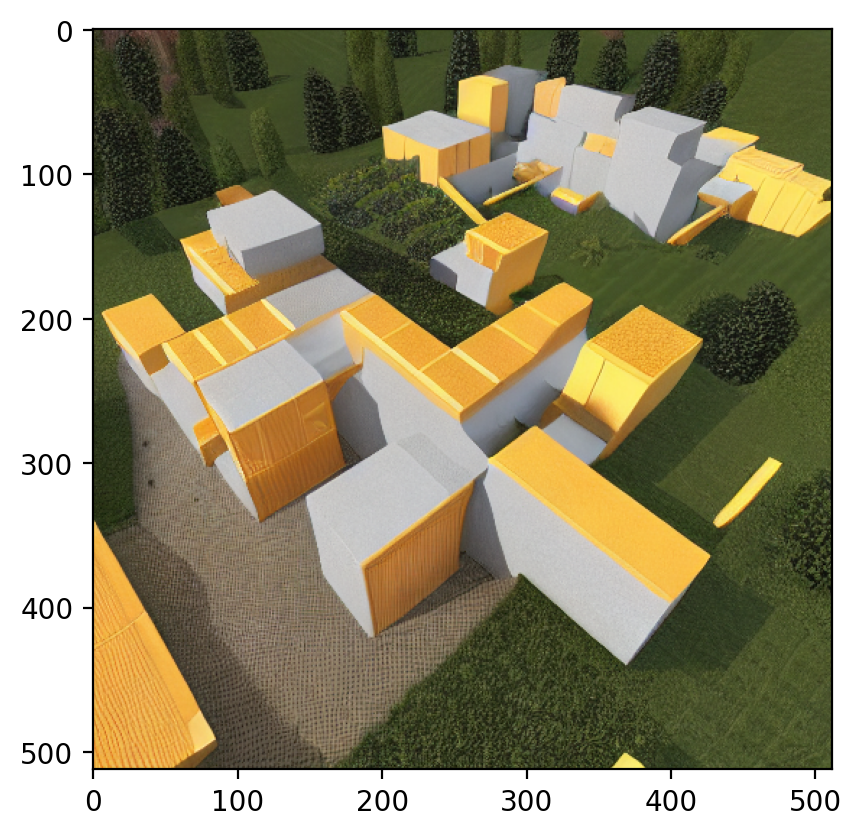

In [ ]:
prompt = "A house build of gold blocks and a money garden"
image = pipe(prompt).images[0] # in PIL format

plt.imshow(image)

Let's unpack the pipeline and run its inference ourselves.

We start with a sampled random noise $z_T \sim \mathcal{N}(0,1)$ living in the latent domain and iteratively denoise it using a UNet with attention blocks. To generate images based on a text description, Stable Diffusion integrates text information using cross-attention layers with text embeddings taken from a pretrained backbone, [CLIP](https://arxiv.org/abs/2103.00020). Once we denoised the latents, we apply VAE decoder to map latents back into the pixel space. See the diagram below:

<p align="left">
<img src="https://raw.githubusercontent.com/patrickvonplaten/scientific_images/master/stable_diffusion.png" alt="sd-pipeline" width="500"/>
</p>

So, to run Stable Diffusion, we need VAE, Text Encoder (CLIP), and a denoising model (UNet). Let's load them separately using the `subfolder` option:

In [ ]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, PNDMScheduler

vae = AutoencoderKL.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="vae").to(device)

# We also load tokenizer as a preprocessor for CLIP
tokenizer = CLIPTokenizer.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="text_encoder").to(device)

unet = UNet2DConditionModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="unet").to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: CompVis/stable-diffusion-v1-4
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In the lecture, we discussed that the Denoising Score Matching view of diffusion uses many different noise levels $\sigma$. The reason is that for small $\sigma$, the score $\nabla \log p_\sigma(x)$ is only accurate locally. If we only trained at small noise levels, we would not be able to start from a random point, since such points lie far from the data distribution and the model would not know how to move these points toward realistic images.

Using many $\sigma$ values allows us to gradually transition from highly noisy samples to clean images. At large $\sigma$, the distribution is smooth and the score provides coarse, global guidance. As $\sigma$ decreases, the model refines the sample with increasingly detailed, local corrections.

To learn this progression, the model $s_{\theta}(x, \sigma)$ must understand how the score changes with $\sigma$. This requires fine-grained supervision across the noise levels. In practice, we therefore train with many $\sigma$ values (e.g., 1000), which results in a dense discretization and a smooth, consistent dependency on $\sigma$.

After training, the model does not simply memorize scores at specific $\sigma$ values, but learns how the score evolves as $\sigma$ changes. This smooth dependency allows us to evaluate the model at arbitrary noise levels and even skip some of them during inference to speed up sampling.

One example of such a method is [DDIM](https://arxiv.org/abs/2010.02502).

From the forward diffusion process (Eq. 4 in DDPM), we know that for any timestep $\tau$:

$$
x_{\tau} = \sqrt{\overline{\alpha_{\tau}}}\, x_0 + \sqrt{1 - \overline{\alpha_{\tau}}}\epsilon, \quad \epsilon \sim \mathcal{N}(0,1).
$$

This holds for all $\tau$.

At inference time, the model predicts the noise $\epsilon_\theta(x_t, t)$, which allows us to estimate the clean image:

$$
\hat{x}_0 =
\frac{1}{\sqrt{\overline{\alpha_t}}}
\left(
x_t - \sqrt{1 - \overline{\alpha_t}}\, \epsilon_\theta(x_t, t)
\right)
$$

This expression is obtained by rearranging the forward equation and replacing the true noise $\epsilon$ with the model prediction.

Since the forward equation is valid for any timestep, we can plug $\hat{x}_0$ back into it to directly compute a sample at an earlier timestep $\tau < t$:

$$
x_{\tau} =
\sqrt{\overline{\alpha_{\tau}}}\, \hat{x}_0
+ \sqrt{1 - \overline{\alpha_{\tau}}} \epsilon, \quad \epsilon \sim \mathcal{N}(0,1)
$$

This allows us to skip intermediate steps and jump across timesteps during inference.

In principle, one could jump directly from $T$ to $0$. However, $\hat{x}_0$ is only an approximation, and large jumps amplify its error, leading to poor sample quality. In practice, we therefore use a reduced but still reasonably dense sequence of timesteps (e.g., 50 instead of 1000, i.e., we take each $\frac{1000}{50}=20$-th noise level: 1000, 980, 960...), achieving a good trade-off between speed and quality.

This approach works because during training, the timestep $t$ is sampled uniformly at random. As a result, the model learns to denoise from any noise level and develops a smooth understanding (given dense-enough discretization, as we discussed above) of how the score depends on $\sigma$, making it possible to skip some of $\sigma$. This enables flexible, non-sequential sampling strategies at inference time.

Let's use DDIM for our Stable Diffusion.

In [ ]:
from diffusers import DDIMScheduler

scheduler = DDIMScheduler.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="scheduler")
scheduler.set_timesteps(50)

Another important aspect to understand is the role of the VAE in latent diffusion models.

Originally, a VAE with encoder $\phi$ and decoder $\theta$ is trained by maximizing the ELBO:
$$
\mathbb{E}_{q_{\phi}(z \mid x)}[\log p_{\theta}(x \mid z)] - \mathrm{KL}(q_{\phi}(z \mid x) \| p(z)),
$$
where the prior is typically chosen as $p(z) = \mathcal{N}(0, I)$.

The KL term can be decomposed as:
$$
\mathbb{E}_{p(x)}\left[\mathrm{KL}(q_{\phi}(z \mid x) \| p(z))\right]
=
\mathrm{KL}(q_{\phi}(z) \| p(z)) + I(x; z),
$$
where $q_{\phi}(z)$ is the aggregated posterior and $I(x; z)$ is the mutual information.

Thus, the objective contains three competing effects. The reconstruction term encourages high mutual information so that $z$ retains enough information to reconstruct $x$. The distribution matching term encourages $q_{\phi}(z)$ to match the prior $\mathcal{N}(0, I)$. At the same time, the KL term also penalizes the mutual information $I(x; z)$, effectively encouraging compression.

We model:
$$
q_{\phi}(z \mid x) = \mathcal{N}(\mu(x), \sigma(x)^2)
$$

Minimizing the KL term encourages $\mu(x)$ to stay close to $0$ and $\sigma(x)$ to stay close to $1$. However, the reconstruction term requires different inputs $x$ to map to distinguishable latent representations. This creates a fundamental tension: the KL term pushes latent codes to overlap, while the reconstruction term pushes them apart.

If the KL term is too strong, many different inputs may map to overlapping latent regions. In that case, the decoder receives ambiguous inputs and learns to predict the conditional expectation:
$$
\hat{x}(z) = \mathbb{E}[x \mid z],
$$
which results in blurry generations.

While enforcing $q_{\phi}(z) \approx \mathcal{N}(0, I)$ allows VAE-driven generation by sampling $z \sim \mathcal{N}(0, I)$, it comes at the cost of reconstruction quality. In latent diffusion models, we do not rely on the VAE for generation. Instead, VAE is used purely as compression and diffusion models learn the latent distribution $q(z)$ directly. Therefore, we prioritize high-quality reconstruction over matching the prior.

This is achieved using the [$\beta$-VAE](https://openreview.net/forum?id=Sy2fzU9gl) formulation:
$$
\mathbb{E}_{q_{\phi}(z \mid x)}[\log p_{\theta}(x \mid z)] - \beta \,\mathrm{KL}(q_{\phi}(z \mid x) \| p(z))
$$

Choosing $\beta \ll 1$ weakens the KL constraint, improves reconstruction quality, and allows latent representations to better separate different inputs.

Using the reparameterization trick:
$$
z = \mu(x) + \sigma(x)\epsilon, \quad \epsilon \sim \mathcal{N}(0,1)
$$

The reconstruction term favors stable latents, which pushes $\sigma(x)$ toward zero. When the KL term is weak, this leads to:
$$
q_{\phi}(z \mid x) \approx \delta(z - \mu(x))
$$

Thus, the encoder becomes nearly deterministic, and the aggregated distribution $q_{\phi}(z)$ is approximately the distribution of $\mu(x)$ over the dataset, which is generally not Gaussian and may have arbitrary variance.

In DDPM, the forward process is:
$$
z_t = \sqrt{\bar{\alpha}_t} z_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)
$$

This process assumes that the signal $z_0$ and noise are on comparable scales. However, with $\beta$-VAE, the latent distribution does not necessarily have unit variance. If the variance of $z_0$ is too large, the noise is ineffective; if it is too small, the signal is destroyed too quickly.

To address this, latents are rescaled:
$$
z' = c \cdot z
$$

where $c$ is chosen such that:
$$
\mathrm{Var}(z') \approx 1
$$

In practice, $c$ is estimated from dataset statistics of $\mu(x)$. Before decoding, the scaling is inverted:
$$
z = \frac{z'}{c}
$$

### Task 1 [0.5 pts]

1. [0.15] Given the CLIP model above, create a function `get_text_embeddings` that will convert a raw text string into textual embeddings.

2. [0.05] Create a `get_latents` function that will create $z_T$ (random noise).

3. [0.10] Create a `decode_latents` function that will take predicted $z_0$, scale it using $c$ set to `vae.config.scaling_factor` and pass through the VAE decoder above.

Note that for stability, images are transformed from $[0,1]$ to $[-1,1]$ to have zero-mean, so your `decode_latents` needs to account for that.

4. [0.20] Create a `denoise_latents` function that will go over $t$ from the `scheduler` and iteratively denoise $z_t$ using `scheduler.step` and `unet` (see `diffusers` documentation). Initialize $z_t$ with $z_T$ and do not forget about the text conditioning.


In [ ]:
from diffusers.utils.torch_utils import randn_tensor
from tqdm.auto import tqdm

@torch.no_grad()
@torch.no_grad()
def get_text_embeddings(text):
    t = tokenizer(
        text,
        padding="max_length",
        max_length=tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    )
    return text_encoder(t.input_ids.to(device))[0]

@torch.no_grad()
def get_latents(h, w):
    vae_scale_factor = 2 ** (len(vae.config.block_out_channels) - 1)
    shape = (1, unet.config.in_channels, h // vae_scale_factor, w // vae_scale_factor)
    z_T = randn_tensor(shape, device=device, dtype=unet.dtype)
    z_T = z_T * scheduler.init_noise_sigma
    return z_T

@torch.no_grad()
def decode_latents(z):
    x = vae.decode(z / vae.config.scaling_factor, return_dict=False)[0]
    x = (x / 2 + 0.5).clamp(0, 1)
    x = x.detach().cpu().permute(0, 2, 3, 1).float().numpy()
    return x

@torch.no_grad()
def denoise_latents(z_T, text_embeddings):
    z = z_T
    for t in tqdm(scheduler.timesteps):
        latent_model_input = scheduler.scale_model_input(z, t)
        noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings.to(unet.dtype), return_dict=False)[0]
        z = scheduler.step(noise_pred, t, z, return_dict=False)[0]
    return z

Run your functions with the prompt from the start of the notebook and show the result here:

  0%|          | 0/50 [00:00<?, ?it/s]

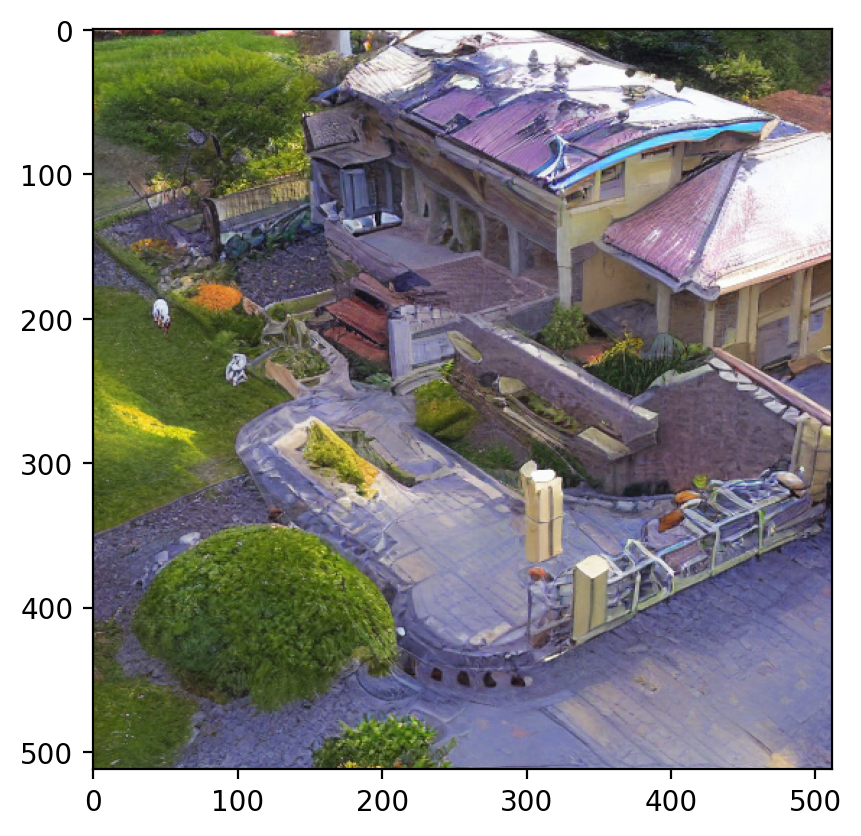

In [ ]:
emb = get_text_embeddings(prompt)
z = denoise_latents(get_latents(512, 512), emb)
plt.imshow(decode_latents(z).squeeze(0))

### Classifier-Free Guidance Experiments

In generative models, there is a well-known concept of *vector arithmetic*. This was first observed in GANs in [Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks (Section 6.3.2)](https://arxiv.org/abs/1511.06434). The idea is that if one noise vector corresponds to object $x_1$ and another to object $x_2$, then averaging these vectors produces something resembling a mixture of both. More generally, one can modify an object by moving its latent representation along a “direction” corresponding to a specific feature or style.

In diffusion models, when we predict noise $\epsilon$ using a U-Net conditioned on text, we obtain $\epsilon_{\text{text}}$. This prediction implicitly contains two types of information:

1. General image structure (what makes an image look plausible), independent of the prompt  
2. Prompt-specific information (what makes the image match the text, e.g., "a house")

We can also compute an unconditional prediction $\epsilon_{\text{uncond}}$ by using an empty prompt. This captures only the general, non-prompt-specific information.

The difference
$$
\epsilon_{\text{text}} - \epsilon_{\text{uncond}}
$$
can be interpreted as a *direction* in the latent space that pushes the prediction toward the prompt.

Using this, we define:
$$
\epsilon_{\text{total}} = \epsilon_{\text{uncond}} + s \cdot (\epsilon_{\text{text}} - \epsilon_{\text{uncond}})
$$

where $s$ is the **guidance scale**:
- $s = 0$: purely unconditional generation  
- $s = 1$: standard conditional prediction  
- $s > 1$: stronger alignment with the prompt  

This method is known as *classifier-free guidance*. See [Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598) for more details.

Let's now rewrite the code from Task 1 using this formulation and explore how different values of $s$ affect generation.

### Task 2 [0.5 pts]

[0.4] Create a `denoise_latents_cfg` function that will compute $\epsilon_{\text{total}}$ for a provided scale $s$.

[0.1] Think how to compute $\epsilon_{\text{total}}$ in a single forward pass and write your function in the corresponding way.

In [ ]:
@torch.no_grad()
def denoise_latents_cfg(z, emb, uncond, s):
    for t in tqdm(scheduler.timesteps):
        latent_model_input = scheduler.scale_model_input(torch.cat([z, z]), t)
        e = unet(
            latent_model_input,
            t,
            encoder_hidden_states=torch.cat([uncond, emb]).to(unet.dtype),
            return_dict=False
        )[0]
        e_uncond, e_text = e.chunk(2)
        e = e_uncond + s * (e_text - e_uncond)
        z = scheduler.step(e, t, z, return_dict=False)[0]
    return z

Show the result for $s=0, s=1, s=10$.

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

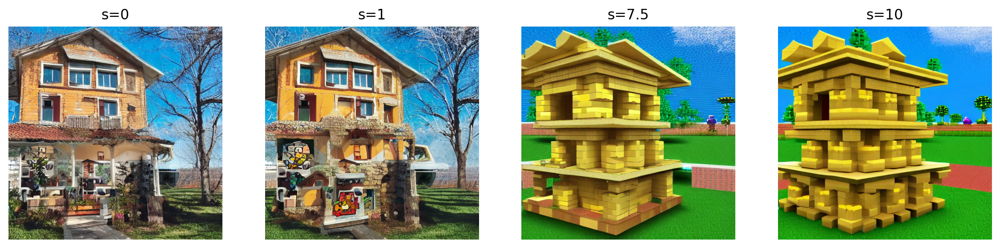

In [ ]:
emb = get_text_embeddings(prompt)
uncond = get_text_embeddings("")
z_T = get_latents(512, 512)

imgs = []
for s in [0, 1, 7.5, 10]:
    z = denoise_latents_cfg(z_T.clone(), emb, uncond, s)
    imgs.append(decode_latents(z)[0])

plt.figure(figsize=(15,5))
for i, s in enumerate([0, 1, 7.5, 10]):
    plt.subplot(1, 4, i+1)
    plt.imshow(imgs[i])
    plt.title(f"s={s}")
    plt.axis("off")
plt.show()

### Task 3 [1 pts]

Your task is to understand and analyze the impact of the scaling factor $s$. To do so, you should run the classifier-free guidance for different $s$. Think of a reasonable set of possible $s$ options that will allow you to understand the affect of $s$ fully (think about reasonable cases, meaningful cases, and corner cases). Think about a nice visualization of your experiments.

In [ ]:
def cfg_exp(scales, prompt):
    l = len(scales)
    emb = get_text_embeddings(prompt)
    uncond = get_text_embeddings("")
    z_T = get_latents(512, 512)

    imgs = []
    for s in scales:
        z = denoise_latents_cfg(z_T.clone(), emb, uncond, s)
        imgs.append(decode_latents(z)[0])

    rows = (l - 1)//4 + 1
    plt.figure(figsize=(4*4, rows*4))
    for i, s in enumerate(scales):
        plt.subplot(rows, 4, i+1)
        plt.imshow(imgs[i])
        plt.title(f"s={s}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

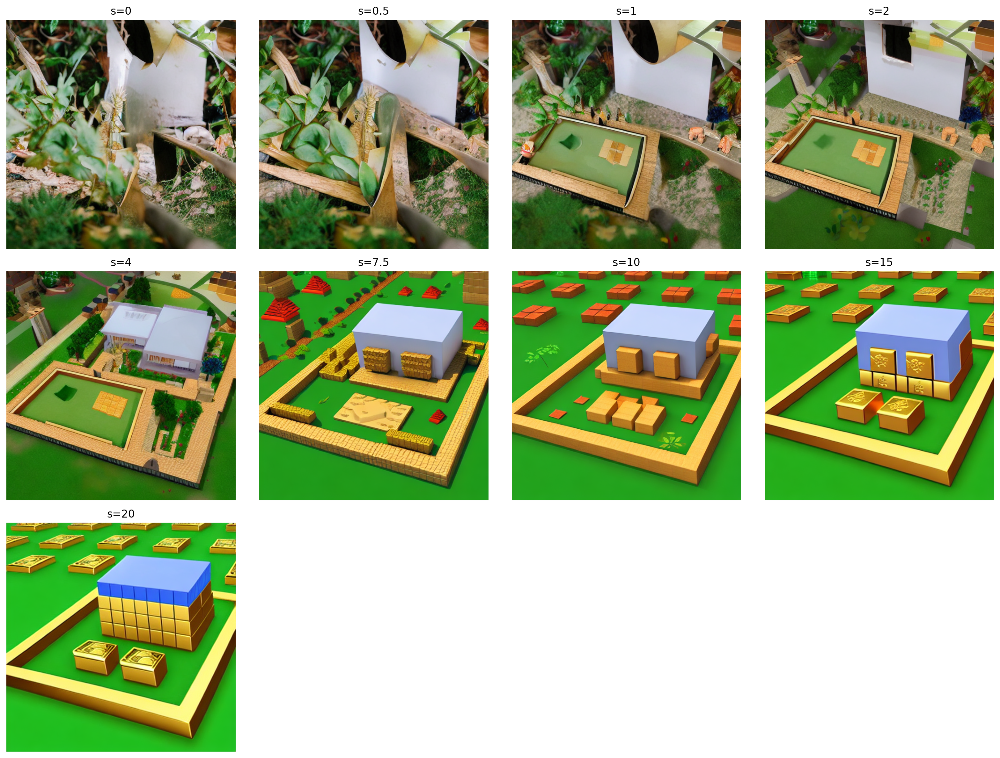

In [ ]:
scales = [0, 0.5, 1, 2, 4, 7.5, 10, 15, 20]
cfg_exp(scales, prompt)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

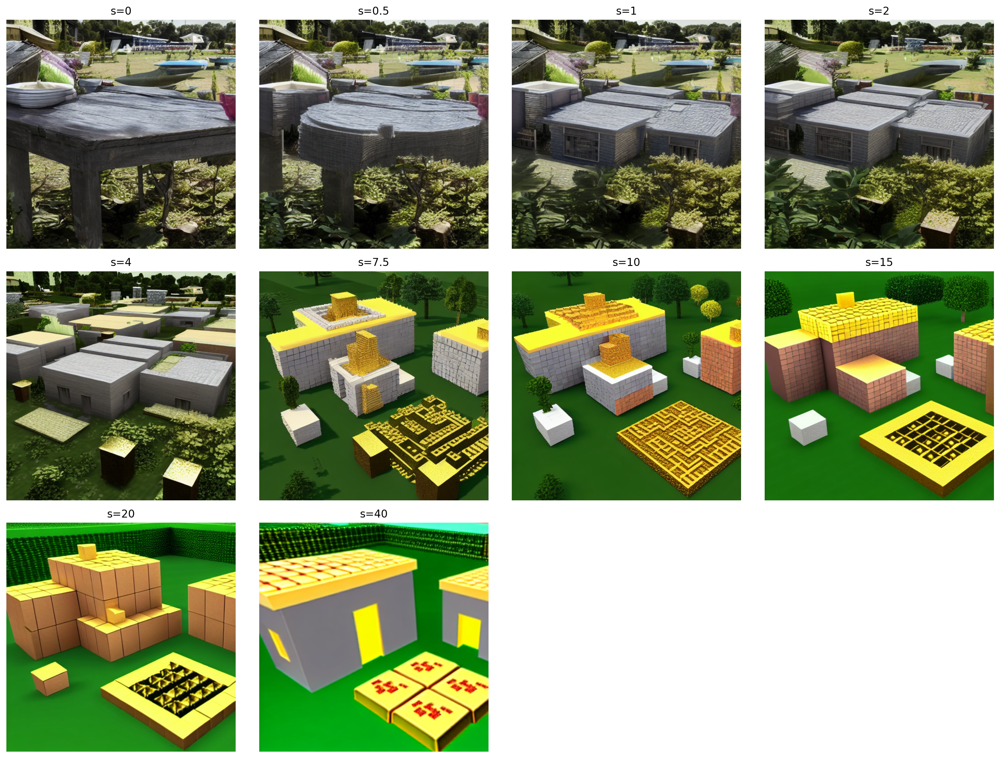

In [ ]:
scales = [0, 0.5, 1, 2, 4, 7.5, 10, 15, 20, 40]
cfg_exp(scales, prompt)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

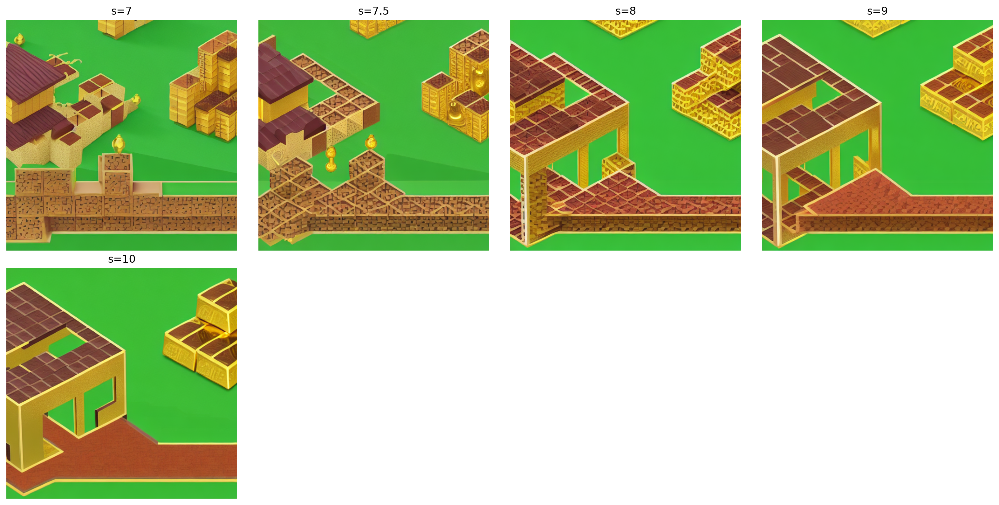

In [ ]:
scales = [7, 7.5, 8, 9, 10]
cfg_exp(scales, prompt)

Reflect on the generated images for each $s$. How different values of $s$ impact the generation?

s = 0: у нас нет никакой связи с промптом, но зато у нас детализированная и реалистичная картинка

s = 0.5: виден шаг в сторону промпта, у нас разма-алась немножко картинка, но пока есть только какая-то размазанная часть промпта, а детали и реалистичность остались с начала.

s = 1 - 2 : видим реалистичность, много деталей и отдельные появляющиеся части связанные с промптом

s = 4: видим все еще детали и реалистичную картинку(хотя чуть меньше), но при этом какие-то глобальные вещи от промпта, пока не детали, а скорее общюю картину.

s = 7.5 - 10: уже виден промпт, пока есть детали, но картинка уже менее реалистичная

s = 15, 20, 40: четкий промпт, но деталей мало, картинка совсем не реалистичная, в ней мало структуры и глубины.

поэтому иду смотреть 7-10 внимательнее

s = 8-9 размываются текстуры и детали, картинка шаблонная какая-то

s = 10 промпт победил и у нас получились блоки золота вместо здания, картинка совсем без деталей и очень плоская

s = 7-7.5 а вот тут и детали хорошие и золото по стенам стекает, оптимально (хотя и все равно не очень, но у примера не лучше)

## Part 2: Implementing a Diffusion Model

**Note** Everything from the `diffusers` library is banned in this part, except for VAE. **Solutions from the internet/LLM are also banned**.

In this part, we will go through [Denoising Diffusion Probabilistic Models (DDPM)](https://arxiv.org/abs/2006.11239) and implement it. Our final goal is to create a Latent Diffusion Model that will be able to generate high-resolution images. However, diving straight into this task is too complicated and it is not how one should approach a paper re-implementation or creation of a pipeline (training/inference) from scratch in general. We need to start with something simpler and build the final model step-by-step. Here is our plan:

1. Instead of complicated images, we will start with a toy dataset. Since the dataset is simple, a correct (or at least "more or less" correct) pipeline will be able to work on it without issues. If our model fails on it, then, we definitely did a mistake somewhere and need to debug before moving on with a more complicated dataset.
2. As you remember, in the diffusion process, a model is trained to predict added noise. Even though current SOTA models use [U-Net](https://arxiv.org/abs/1505.04597) or [ViT](https://arxiv.org/abs/2010.11929) backbones, the process itself does not actually require any specific architecture. Hence, before implementing a complicated model, we should first check our pipeline (diffusion, its inference and training) with a simple architecture, such as an MLP, and only if it works, we can move on with a U-Net or something else.
3. Once we make sure that we can do proper generations on a toy dataset with an MLP-based diffusion, we will implement U-Net and run diffusion on high-resolution images.

For the toy dataset, we will use the Moon Dataset from `sklearn`.

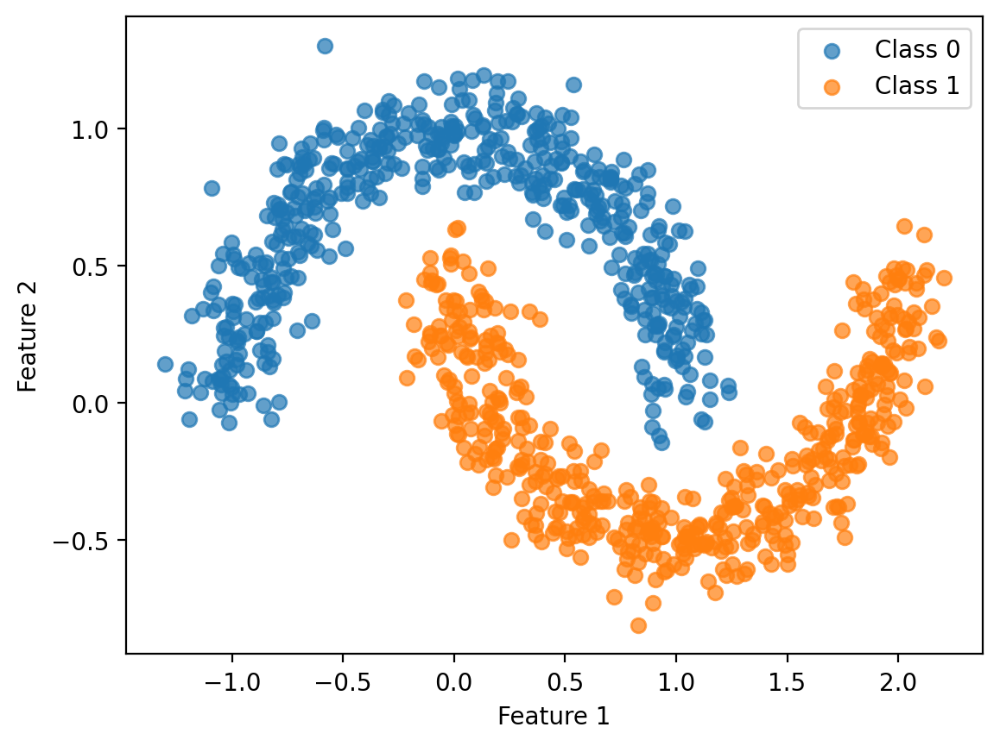

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.1, random_state=1)

plt.scatter(X[y==0, 0], X[y==0, 1], label="Class 0", alpha=0.7)
plt.scatter(X[y==1, 0], X[y==1, 1], label="Class 1", alpha=0.7)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

We aim to build a Diffusion class that progressively injects noise into the moon-shaped data (forward process) and then learns to reverse this by removing the noise (backward process). To train this model, we need suitable training data, so we'll construct a simple `PyTorch` dataset. For better numerical stability, the data will be normalized to have a mean of zero and a standard deviation of one.

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class MoonDataset(Dataset):

    def __init__(self, n=200):
        X, y = make_moons(n_samples=n, noise=0.1, random_state=1)
        self.X = torch.tensor(X).to(torch.float32)
        self.y = torch.tensor(y)
        self.n = n

        self.mean = self.X.mean(0)
        self.std = self.X.std(0)


    def __len__(self):
        return self.n

    def __getitem__(self, index):
        X = self.X[index]
        # normalize
        X = (X - self.mean) / self.std
        y = self.y[index]
        return X, y

In [ ]:
dataset = MoonDataset(n=10000)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

### Task 4 [2 pts]

Now, we will implement the DDPM-style diffusion. To do so, read the [paper](https://arxiv.org/abs/2006.11239) and fill-in the gaps in the skelet of the Diffusion class below. See doc-strings for hints.


*Hint*: For improved numerical stability, it is recommended to use $\log \text{Var}$ instead of $\text{Var}$. This is especially helpful for small $\sigma$, as it provides a better numerical range, more stable gradients, and ensures positivity:

$$
\sigma^2 = \exp(\log \text{Var})
$$

**Note**: Ignore class labels for now.

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm


class GaussianDiffusion(nn.Module):
    """
    DDPM Implementation
    """
    def __init__(self, model, image_shape, timesteps=1000, beta_schedule="linear", device=None):
        super().__init__()
        self.model = model
        self.image_shape = image_shape  # e.g. (C,H,W)
        self.T = timesteps
        self.device = device or next(model.parameters()).device

        if beta_schedule == "linear":
            betas = torch.linspace(1e-4, 2e-2, self.T) # See Section 4
        else:
            raise ValueError("Unknown beta_schedule")

        # register buffers
        # we pre-compute common calculations, such as alpha, \overline{alpha}, etc.
        self.register_buffer("betas", betas)
        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, axis=0)
        alphas_cumprod_prev = torch.cat([torch.ones(1), alphas_cumprod[:-1]], dim=0)

        self.register_buffer("alphas", alphas)
        self.register_buffer("alphas_cumprod", alphas_cumprod)
        self.register_buffer("alphas_cumprod_prev", alphas_cumprod_prev)

        self.register_buffer("sqrt_alphas_cumprod", torch.sqrt(alphas_cumprod))
        self.register_buffer("sqrt_one_minus_alphas_cumprod", torch.sqrt(1.0 - alphas_cumprod))
        self.register_buffer("sqrt_recip_alphas", torch.sqrt(1.0 / alphas))

        # posterior q(x_{t-1} | x_t, x_0)
        posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        # clip variance with a very small value (1e-20) before taking log for safety
        posterior_log_variance_clipped = torch.log(torch.clamp(posterior_variance, min=1e-20))
        posterior_mean_coef1 = betas * torch.sqrt(alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        posterior_mean_coef2 = torch.sqrt(alphas) * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

        self.register_buffer("posterior_variance", posterior_variance)
        self.register_buffer("posterior_log_variance_clipped", posterior_log_variance_clipped)
        self.register_buffer("posterior_mean_coef1", posterior_mean_coef1)
        self.register_buffer("posterior_mean_coef2", posterior_mean_coef2)

    def extract(self, a, t, x_shape):
        """
        Extract element at timestamp t from tensor a.

        Args:
          a (Tensor): timestep-dependent tensor (T, )
          t (LongTensor): timestep (B, )
          x_shape (torch.Size): size of x
        Returns:
          out (Tensor): (B, 1, 1, 1...) broadcasted tensor.
            i-th row containts t[i]-th row from a.
        """
        return (a.gather(-1, t)).reshape(t.shape + (1,) * (len(x_shape) - 1))

    @torch.no_grad()
    def q_sample(self, x0, t, noise=None):
        """
        Sample x_t from q(x_t | x_0).
        Eq. 4 from the paper.

        Args:
          x0 (Tensor): start.
          t (LongTensor): timestep (B, )
          noise (Tensor | None): optional noise.
        Returns:
          xt (Tensor): sample from q(x_t | x_0)
        """
        if noise is None:
          noise = torch.randn_like(x0)

        sqrt_alphas_cumprod_t = self.extract(self.sqrt_alphas_cumprod, t, x0.shape)
        sqrt_one_minus_alphas_cumprod_t = self.extract(
            self.sqrt_one_minus_alphas_cumprod, t, x0.shape
        )
        return sqrt_alphas_cumprod_t * x0 + sqrt_one_minus_alphas_cumprod_t * noise

    def q_sample_loop(self, x0, log_step=100):
        """
        Apply q_sample sequentially.
        Also returns intermediate representations.

        Args:
          x0 (Tensor): start.
          log_step (int): return k*log_step-th representation.
        Returns:
          xt (Tensor): final noise.
          x_inter (list[Tensor]): intermediate representations.
        """
        x_inter = []
        xt = x0 # start with x0
        for i in range(self.T):
            noise = torch.randn_like(xt)
            t = torch.full((xt.shape[0],), i, device=xt.device, dtype=torch.long)
            alpha_t = self.extract(self.alphas, t, xt.shape)
            beta_t = self.extract(self.betas, t, xt.shape)
            xt = torch.sqrt(alpha_t) * xt + torch.sqrt(beta_t) * noise
            if i % log_step == 0:
                x_inter.append(xt)
        # append final representation to x_inter
        x_inter.append(xt)
        return xt, x_inter  # typically clamp/convert to [0,1] outside

    def q_posterior(self, x0, xt, t):
        """
        Compite mean, var, and log_var
        for q(x_{t-1} | x_t, x_0).
        Eq. 6 from the paper.

        Args:
          x0 (Tensor): start.
          xt (Tensor): sample after t additions of noise.
          t (LongTensor): timestep (B, )
        Returns:
          mean (Tensor): mean.
          var (Tensor): var.
          log_var (Tensor): log_var.
        """
        posterior_mean = self.extract(self.posterior_mean_coef1, t, x0.shape) * x0 + self.extract(self.posterior_mean_coef2, t, xt.shape) * xt
        posterior_variance = self.extract(self.posterior_variance, t, xt.shape)
        posterior_log_var_clipped = self.extract(self.posterior_log_variance_clipped, t, xt.shape)
        return posterior_mean, posterior_variance, posterior_log_var_clipped


    def p_mean_variance(self, xt, t):
        """
        Compute mean from Eq 11 and variance.
        We use \tilde{\beta} version of variance, a.k.a. fixed-small
        (i.e. the same variance as in q)

        Args:
          xt (Tensor): sample after t additions of noise.
          t (LongTensor): timestep (B, )
        Returns:
          model_mean (Tensor): computed mean.
          posterior_var (Tensor): computer var.
          posterior_log_var (Tensor): computed log_var
        """
        noise = self.model(xt, t)
        sqrt_recip_alphas_t = self.extract(self.sqrt_recip_alphas, t, xt.shape)
        sqrt_one_minus_alphas_cumprod_t = self.extract(self.sqrt_one_minus_alphas_cumprod, t, xt.shape)

        posterior_mean = sqrt_recip_alphas_t * (xt - self.extract(self.betas, t, xt.shape) * noise / sqrt_one_minus_alphas_cumprod_t)
        posterior_variance = self.extract(self.posterior_variance, t, xt.shape)
        posterior_log_variance_clipped = self.extract(self.posterior_log_variance_clipped, t, xt.shape)
        return posterior_mean, posterior_variance, posterior_log_variance_clipped

    @torch.no_grad()
    def p_sample(self, xt, t):
        """
        Sample x_{t-1} from xt and t.

        Combines Eq.1 and p_mean_variance

        Args:
          xt (Tensor): current noisy sample.
          t (LongTensor): (B, ) which timestep to use to get x_{t-1}
        Returns:
          x_{t-1} (Tensor): previous sample.
        """
        # be careful with t==0
        mean, _, log_var = self.p_mean_variance(xt, t)
        mask = (t != 0).float().reshape(xt.shape[0], *((1,) * (xt.dim() - 1)))
        noise = torch.randn_like(xt)
        return mean + mask * torch.exp(0.5 * log_var) * noise

    @torch.no_grad()
    def sample(self, n, log_step=100):
        """
        Sample n images from random noise.

        Args:
          n (int): number of images.
          log_step (int): return k*log_step-th representation.
        Returns:
          x0 (Tensor): x0 from random noise.
          x_inter (list[Tensor]): intermediate representations.
        """
        x_inter = []
        xt = torch.randn(n, *self.image_shape, device=self.device)

        for i in tqdm(reversed(range(self.T))):

            xt = self.p_sample(xt, torch.full((n,), i, device=self.device, dtype=torch.long))
            if (self.T - i - 1) % log_step == 0:
                x_inter.append(xt)

        x_inter.append(xt)
        return xt, x_inter  # typically clamp/convert to [0,1] outside

    def compute_loss(self, x0):
        """
        Compute loss (Eq. 14)

        Args:
          x0 (Tensor): start position.
        """
        noise = torch.randn_like(x0)
        t = torch.randint(0, self.T, (x0.shape[0],), device=self.device, dtype=torch.long)
        return F.mse_loss(self.model(self.q_sample(x0, t, noise), t), noise)


### Task 5 [0.25 pts]

To estimate the added noise, we need a neural network that can approximate $\epsilon$ from the current noisy sample $x_t$ and the timestep $t$. The original DDPM model uses a U-Net architecture, but since our toy dataset is quite simple, a fully connected network (MLP) is enough. This will also allow us to test our pipeline without the complexity of a more advanced architecture implementation.

Design a basic MLP consisting of four Linear layers. Additionally, include timestep embeddings (using `nn.Embedding`) to represent $t$, and concatenate these embeddings with the input before feeding everything into the network.

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, timesteps=1000, time_emb_dim=32):
        super().__init__()
        self.time_embedding = nn.Embedding(timesteps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(input_dim + time_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, xt, t):
        return self.net(torch.cat([xt.view(xt.size(0), -1), self.time_embedding(t.long())], dim=1)).view_as(xt)

### Task 6 [0.5 pts]

Create a training loop for your diffusion model and train it on the moon dataset. Use $T=1000$ timesteps for noise scheduling.

**Note**: In diffusion models, it's common for the loss to plateau after a certain point, yet the sample quality can continue to improve. Therefore, it's important to track additional metrics and periodically generate samples during training to assess whether the outputs are getting better. Make sure to log some generated samples throughout the training process (but we do not expect you to have any metrics at this point, only samples).

In [ ]:
pip install comet_ml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 786.2/786.2 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.3 MB/s eta 0:00:00
  Attempting uninstall: python-box
    Found existing installation: python-box 7.4.1
    Uninstalling python-box-7.4.1:
      Successfully uninstalled python-box-7.4.1


In [ ]:
import comet_ml
comet_ml.login()

Please paste your Comet API key from https://www.comet.com/api/my/settings/
(api key may not show as you type)
Comet API key: ··········


COMET INFO: Valid Comet API Key saved in /root/.comet.config (set COMET_CONFIG to change where it is saved).


COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nrgpmo/hw3-diffusion/be64995d746b408ea6f669b29b23dffe



Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/40 [00:00<?, ?it/s]

COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


Epoch 2:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/40 [00:00<?, ?it/s]

... (1,014 outputs left out)

Epoch 999:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 1000:   0%|          | 0/40 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

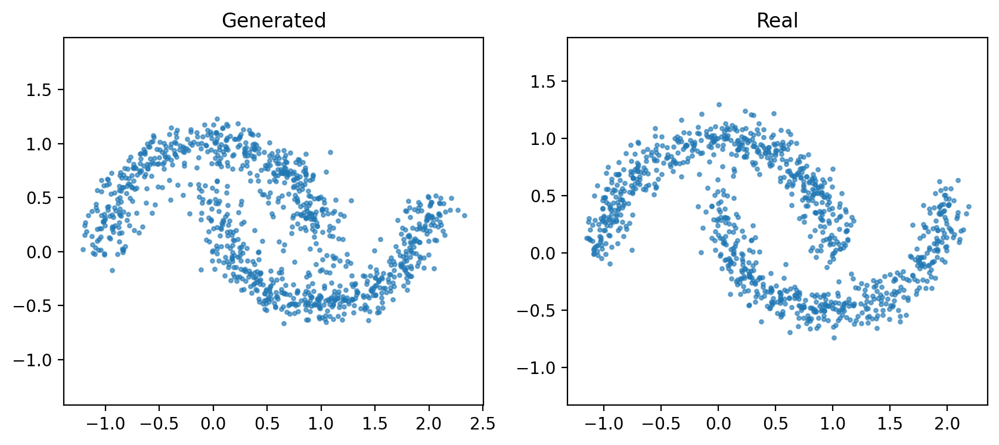

COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ddpm_mlp_two_moons_1
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/be64995d746b408ea6f669b29b23dffe
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [1000] : (0.2253460455685854, 0.8228308588266373)
COMET INFO:     train_step_loss [40000] : (0.024865038692951202, 1.0296754837036133)
COMET INFO:   Others:
COMET INFO:     Name         : ddpm_mlp_two_moons_1
COMET INFO:     notebook_url : https://colab.research.google.com/notebook#fileId=1q9ZtK93WaB9lB7z6ClyB5OPNmrGKazyz
COM

In [ ]:
from comet_ml import Experiment
from tqdm.auto import tqdm
import torch
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

dataset = MoonDataset(n=10000)
loader = DataLoader(dataset, batch_size=256, shuffle=True)

model = MLP(input_dim=2, hidden_dim=256, time_emb_dim=64).to(device)
diffusion = GaussianDiffusion(
    model=model,
    image_shape=(2,),
    timesteps=1000,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

def log_samples(model, exp, epoch, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        samples, _ = model.sample(n)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples[:, 0], samples[:, 1], s=5, alpha=0.6)
    ax.set_title(f"Epoch {epoch + 1}")
    ax.axis("equal")

    exp.log_figure(figure=fig, figure_name=f"{epoch + 1:03d}_epoch")
    plt.close(fig)

def log_final_comparison(model, exp, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        samples, _ = model.sample(n)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()

    real_samples = dataset.X[:n].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].scatter(samples[:, 0], samples[:, 1], s=5, alpha=0.6)
    axes[0].set_title("Generated")
    axes[0].axis("equal")

    axes[1].scatter(real_samples[:, 0], real_samples[:, 1], s=5, alpha=0.6)
    axes[1].set_title("Real")
    axes[1].axis("equal")

    exp.log_figure(figure=fig, figure_name="final_comparison")
    plt.show()
    plt.close(fig)

experiment = Experiment(project_name="hw3-diffusion")
experiment.set_name("ddpm_mlp_two_moons_1")

epochs = 1000
global_step = 0

for epoch in tqdm(range(epochs), desc="Training"):
    diffusion.train()
    epoch_loss = 0.0
    num_steps = len(loader)
    pbar = tqdm(loader, leave=False, desc=f"Epoch {epoch + 1}")

    for step, batch in enumerate(pbar):
        x0, _ = batch
        x0 = x0.to(device)

        optimizer.zero_grad()
        loss = diffusion.compute_loss(x0)
        loss.backward()
        optimizer.step()

        cur_loss = loss.item()
        epoch_loss += cur_loss
        experiment.log_metric("train_step_loss", cur_loss, step=global_step + step)

    epoch_loss /= num_steps
    experiment.log_metric("train_epoch_loss", epoch_loss, step=epoch)
    global_step += num_steps

    if (epoch + 1) % 50 == 0:
        log_samples(diffusion, experiment, epoch, dataset)

log_final_comparison(diffusion, experiment, dataset)

experiment.end()

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: torch, sklearn.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nrgpmo/hw3-diffusion/6160c28a18e7453083365e0c7e9f9fe1

COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 2:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 4:   0%|          | 0/40 [00:00<?, ?it/s]

... (1,193 outputs left out)

Epoch 999:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 1000:   0%|          | 0/40 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

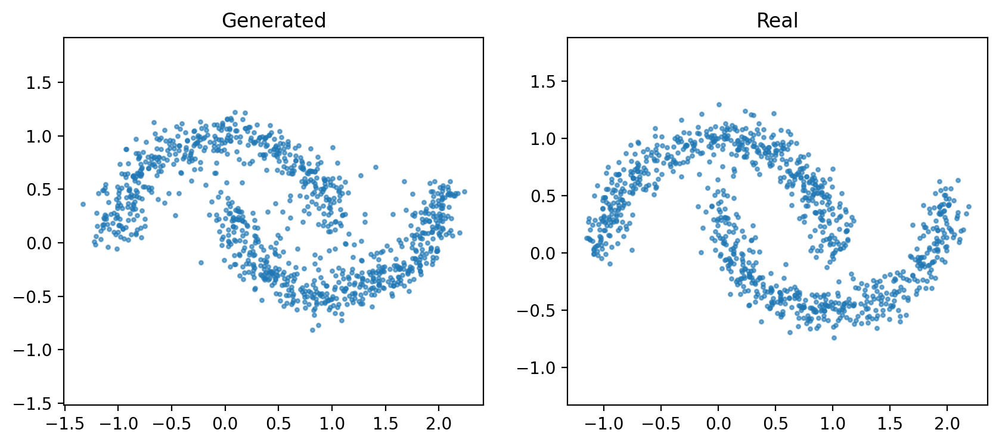

COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ddpm_mlp_two_moons
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/6160c28a18e7453083365e0c7e9f9fe1
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [1000] : (0.22547832652926444, 0.7960145592689514)
COMET INFO:     train_step_loss [40000] : (0.023059887811541557, 1.0658522844314575)
COMET INFO:   Others:
COMET INFO:     Name         : ddpm_mlp_two_moons
COMET INFO:     notebook_url : https://colab.research.google.com/notebook#fileId=1q9ZtK93WaB9lB7z6ClyB5OPNmrGKazyz
COMET 

In [ ]:
from comet_ml import Experiment
from tqdm.auto import tqdm
import torch
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

dataset = MoonDataset(n=10000)
loader = DataLoader(dataset, batch_size=256, shuffle=True)

model = MLP(input_dim=2, hidden_dim=256, time_emb_dim=64).to(device)
diffusion = GaussianDiffusion(
    model=model,
    image_shape=(2,),
    timesteps=1000,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

def log_samples(model, exp, epoch, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        samples, _ = model.sample(n)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples[:, 0], samples[:, 1], s=5, alpha=0.6)
    ax.set_title(f"Epoch {epoch + 1}")
    ax.axis("equal")

    exp.log_figure(figure=fig, figure_name=f"{epoch + 1:03d}_epoch")
    plt.close(fig)

def log_final_comparison(model, exp, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        samples, _ = model.sample(n)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()

    real_samples = dataset.X[:n].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].scatter(samples[:, 0], samples[:, 1], s=5, alpha=0.6)
    axes[0].set_title("Generated")
    axes[0].axis("equal")

    axes[1].scatter(real_samples[:, 0], real_samples[:, 1], s=5, alpha=0.6)
    axes[1].set_title("Real")
    axes[1].axis("equal")

    exp.log_figure(figure=fig, figure_name="final_comparison")
    plt.show()
    plt.close(fig)

experiment = Experiment(project_name="hw3-diffusion")
experiment.set_name("ddpm_mlp_two_moons")

epochs = 1000
global_step = 0

for epoch in tqdm(range(epochs), desc="Training"):
    diffusion.train()
    epoch_loss = 0.0
    num_steps = len(loader)

    for step, batch in tqdm(enumerate(loader), total=num_steps, leave=False, desc=f"Epoch {epoch + 1}"):
        x0, _ = batch
        x0 = x0.to(device)

        optimizer.zero_grad()
        loss = diffusion.compute_loss(x0)
        loss.backward()
        optimizer.step()

        cur_loss = loss.item()
        epoch_loss += cur_loss
        experiment.log_metric("train_step_loss", cur_loss, step=global_step + step)

    epoch_loss /= num_steps
    experiment.log_metric("train_epoch_loss", epoch_loss, step=epoch)
    global_step += num_steps

    if (epoch + 1) % 5 == 0:
        log_samples(diffusion, experiment, epoch, dataset)

log_final_comparison(diffusion, experiment, dataset)

experiment.end()

Now we can sample noise from $\mathcal{N}(0,1)$ and pass it through the diffusion to generate some moon object samples.

Sample 1000 examples and visualize them.

0it [00:00, ?it/s]

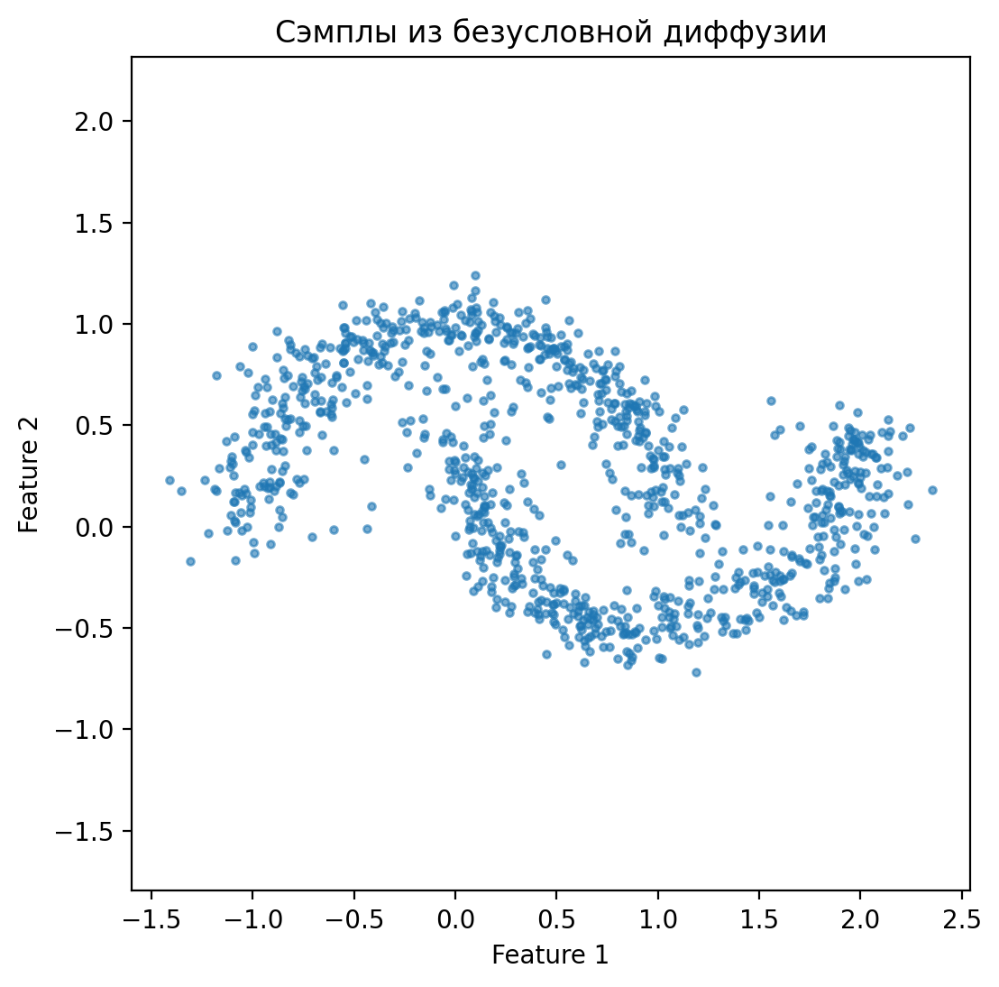

In [ ]:
diffusion.eval()
with torch.no_grad():
    samples, _ = diffusion.sample(1000, log_step=100)

samples = samples.detach().cpu()
samples = samples * dataset.std + dataset.mean  # denormalize

plt.figure(figsize=(6, 6))
plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.6)
plt.title("Сэмплы из безусловной диффузии")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.axis("equal")
plt.show()

### Task 7 [0.25 pts]

If you followed the previous steps correctly, your generations should look similar to the moons. However, we haven't used classes yet. Let's introduce them now. We only need to update the model (so it gets class label as input as well) and the section of the diffusion class where we pass inputs to the model.

$$
\epsilon_{\theta}(x_t, t, y), \text{where $y$ is the class}
$$

In [ ]:
class ConditionalGaussianDiffusion(GaussianDiffusion):

    def p_mean_variance(self, xt, t, y=None):
        noise = self.model(xt, t, y)
        sqrt_recip_alphas_t = self.extract(self.sqrt_recip_alphas, t, xt.shape)
        sqrt_one_minus_alphas_cumprod_t = self.extract(self.sqrt_one_minus_alphas_cumprod, t, xt.shape)

        posterior_mean = sqrt_recip_alphas_t * (xt - self.extract(self.betas, t, xt.shape) * noise / sqrt_one_minus_alphas_cumprod_t)
        posterior_variance = self.extract(self.posterior_variance, t, xt.shape)
        posterior_log_variance_clipped = self.extract(self.posterior_log_variance_clipped, t, xt.shape)
        return posterior_mean, posterior_variance, posterior_log_variance_clipped

    @torch.no_grad()
    def p_sample(self, xt, t, y=None):
        mean, _, log_var = self.p_mean_variance(xt, t, y)
        mask = (t != 0).float().reshape(xt.shape[0], *((1,) * (xt.dim() - 1)))
        noise = torch.randn_like(xt)
        return mean + mask * torch.exp(0.5 * log_var) * noise

    @torch.no_grad()
    def sample(self, n, log_step=100, y=None):
        x_inter = []
        xt = torch.randn(n, *self.image_shape, device=self.device)

        for i in tqdm(reversed(range(self.T)), total=self.T, desc="Reverse diffusion", leave=False):
            xt = self.p_sample(xt, torch.full((n,), i, device=self.device, dtype=torch.long), y)
            if (self.T - i - 1) % log_step == 0:
                x_inter.append(xt)

        x_inter.append(xt)
        return xt, x_inter  # typically clamp/convert to [0,1] outside

    def compute_loss(self, x0, y=None):
        noise = torch.randn_like(x0)
        t = torch.randint(0, self.T, (x0.shape[0],), device=self.device, dtype=torch.long)
        return F.mse_loss(self.model(self.q_sample(x0, t, noise), t, y), noise)

For classes, we will again use `nn.Embedding` and just concatenate it with other input before passing to the MLP. Create an updated class:

In [ ]:
class MLP_Conditional(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, time_steps=1000, time_emb_dim=32, num_classes=2, class_emb_dim=32):
        super().__init__()
        self.time_embedding = nn.Embedding(time_steps, time_emb_dim)
        self.class_embedding = nn.Embedding(num_classes, class_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(input_dim + time_emb_dim + class_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, xt, t, y=None):
        return self.net(torch.cat([xt.view(xt.size(0), -1), self.time_embedding(t.long()), self.class_embedding(y)], dim=-1)).view_as(xt)

Train a conditional version of your model:

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nrgpmo/hw3-diffusion/8b0812350a824d8497d1ebca6ab1379c



Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/40 [00:00<?, ?it/s]

COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


Epoch 2:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/40 [00:00<?, ?it/s]

... (1,006 outputs left out)

Epoch 998:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 999:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch 1000:   0%|          | 0/40 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

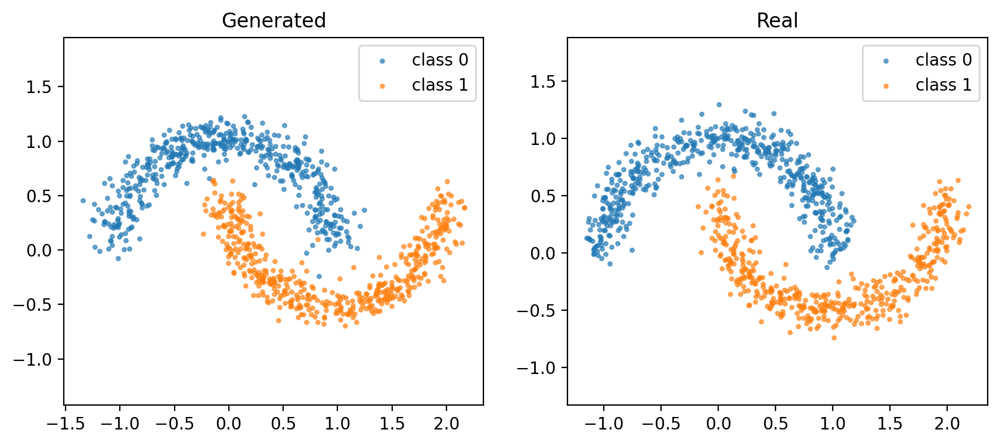

COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : ddpm_mlp_two_moons_conditional_1
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/8b0812350a824d8497d1ebca6ab1379c
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [1000] : (0.17777290306985377, 0.817417886853218)
COMET INFO:     train_step_loss [40000] : (0.017650574445724487, 1.1397340297698975)
COMET INFO:   Others:
COMET INFO:     Name         : ddpm_mlp_two_moons_conditional_1
COMET INFO:     notebook_url : https://colab.research.google.com/notebook#fileId=1q9ZtK93WaB9l

In [ ]:
from comet_ml import Experiment
from tqdm.auto import tqdm
import torch
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

dataset = MoonDataset(n=10000)
loader = DataLoader(dataset, batch_size=256, shuffle=True)

model = MLP_Conditional(input_dim=2, hidden_dim=256, time_emb_dim=64, num_classes=2, class_emb_dim=64).to(device)
diffusion = ConditionalGaussianDiffusion(
    model=model,
    image_shape=(2,),
    timesteps=1000,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

def log_samples(model, exp, epoch, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        y = torch.cat([
            torch.zeros(n // 2, dtype=torch.long),
            torch.ones(n - n // 2, dtype=torch.long)
        ]).to(device)
        samples, _ = model.sample(n, y=y)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()
    y = y.cpu().numpy()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples[y == 0, 0], samples[y == 0, 1], s=5, alpha=0.6, label="class 0")
    ax.scatter(samples[y == 1, 0], samples[y == 1, 1], s=5, alpha=0.6, label="class 1")
    ax.set_title(f"Epoch {epoch + 1}")
    ax.axis("equal")
    ax.legend()

    exp.log_figure(figure=fig, figure_name=f"{epoch + 1:03d}_epoch")
    plt.close(fig)

def log_final_comparison(model, exp, dataset, n=1000):
    model.eval()
    with torch.no_grad():
        y = torch.cat([
            torch.zeros(n // 2, dtype=torch.long),
            torch.ones(n - n // 2, dtype=torch.long)
        ]).to(device)
        samples, _ = model.sample(n, y=y)

    samples = samples.detach().cpu()
    samples = samples * dataset.std + dataset.mean
    samples = samples.numpy()
    y = y.cpu().numpy()

    real_samples = dataset.X[:n].cpu().numpy()
    real_labels = dataset.y[:n].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].scatter(samples[y == 0, 0], samples[y == 0, 1], s=5, alpha=0.6, label="class 0")
    axes[0].scatter(samples[y == 1, 0], samples[y == 1, 1], s=5, alpha=0.6, label="class 1")
    axes[0].set_title("Generated")
    axes[0].axis("equal")
    axes[0].legend()

    axes[1].scatter(real_samples[real_labels == 0, 0], real_samples[real_labels == 0, 1], s=5, alpha=0.6, label="class 0")
    axes[1].scatter(real_samples[real_labels == 1, 0], real_samples[real_labels == 1, 1], s=5, alpha=0.6, label="class 1")
    axes[1].set_title("Real")
    axes[1].axis("equal")
    axes[1].legend()

    exp.log_figure(figure=fig, figure_name="final_comparison")
    plt.show()
    plt.close(fig)

experiment = Experiment(project_name="hw3-diffusion")
experiment.set_name("ddpm_mlp_two_moons_conditional_1")

epochs = 1000
global_step = 0

for epoch in tqdm(range(epochs), desc="Training"):
    diffusion.train()
    epoch_loss = 0.0
    num_steps = len(loader)
    pbar = tqdm(loader, leave=False, desc=f"Epoch {epoch + 1}")

    for step, batch in enumerate(pbar):
        x0, y = batch
        x0 = x0.to(device)
        y = y.to(device).long()

        optimizer.zero_grad()
        loss = diffusion.compute_loss(x0, y)
        loss.backward()
        optimizer.step()

        cur_loss = loss.item()
        epoch_loss += cur_loss
        experiment.log_metric("train_step_loss", cur_loss, step=global_step + step)

    epoch_loss /= num_steps
    experiment.log_metric("train_epoch_loss", epoch_loss, step=epoch)
    global_step += num_steps

    if (epoch + 1) % 80 == 0:
        log_samples(diffusion, experiment, epoch, dataset)

log_final_comparison(diffusion, experiment, dataset)

experiment.end()

### Task 8 [0.5 pts]

Let's sample from this Conditional Diffusion. Sample random classes uniformly and then samples for each class. Visualize the results:

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

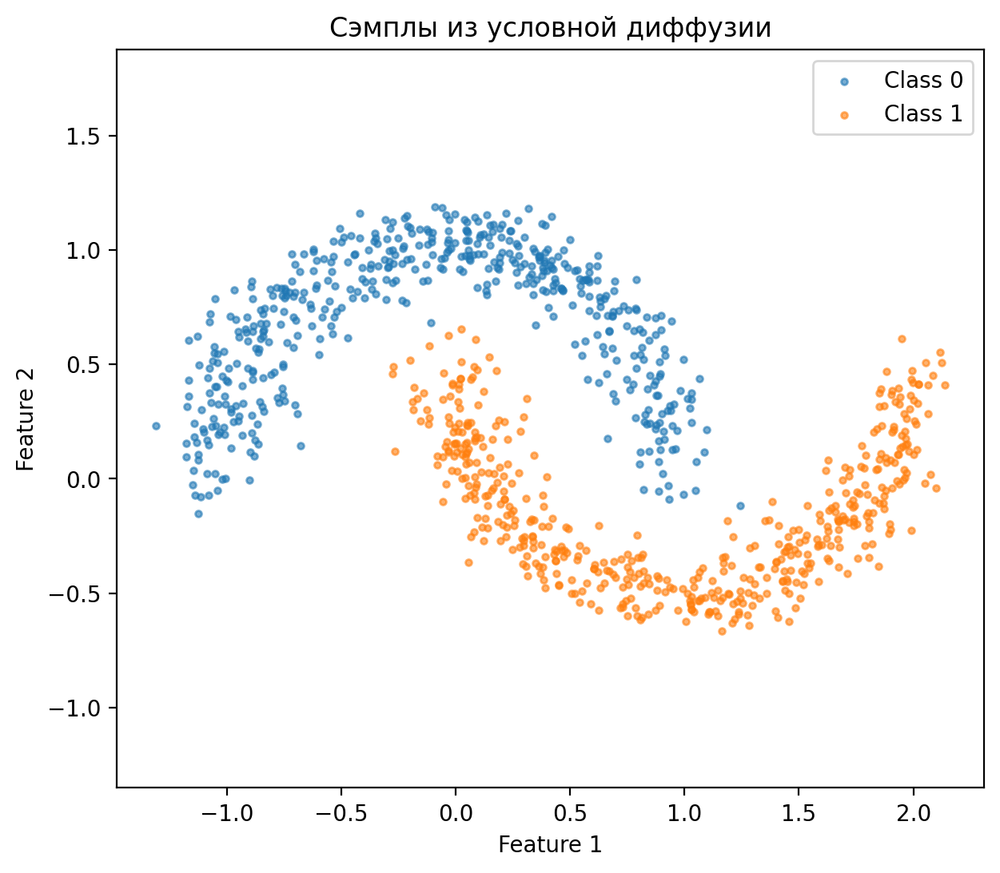

In [ ]:
n_per_class = 500
class_labels = torch.cat([
    torch.zeros(n_per_class, dtype=torch.long),
    torch.ones(n_per_class, dtype=torch.long),
]).to(device)

with torch.no_grad():
    samples, _ = diffusion.sample(2 * n_per_class, y=class_labels, log_step=100)

samples = samples.detach().cpu()
samples = samples * dataset.std + dataset.mean
labels = class_labels.cpu()

plt.figure(figsize=(7, 6))
plt.scatter(samples[labels == 0, 0], samples[labels == 0, 1], s=8, alpha=0.6, label="Class 0")
plt.scatter(samples[labels == 1, 0], samples[labels == 1, 1], s=8, alpha=0.6, label="Class 1")
plt.legend()
plt.title("Сэмплы из условной диффузии")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.axis("equal")
plt.show()


Again, we get moon-like shapes, as we expected. However, we see that class conditioning also produced sharper moons. Why?

 вместо того чтобы предсказывать одно смешанное распределение, модель учится предсказывать 2 более простых отдельных, кучных и узких. И поэтому семплы резче и стабильнее, потому что ей реже надо усреднять две луны между собой, засчет чего как раз у нас меньше точек между лунами и они больше отделены. Потому что как раз у точек между не смешиваются шумы от двух лун.

### Task 9 [0.5 pts]

Let's see how $x_t$ changes over time in the forward and reverse processes.

For the forward process, we will provide moons from the dataset as $x_0$. Compute final and intermediate representations (each 100-th $t$). Do-not forget about denormalization.

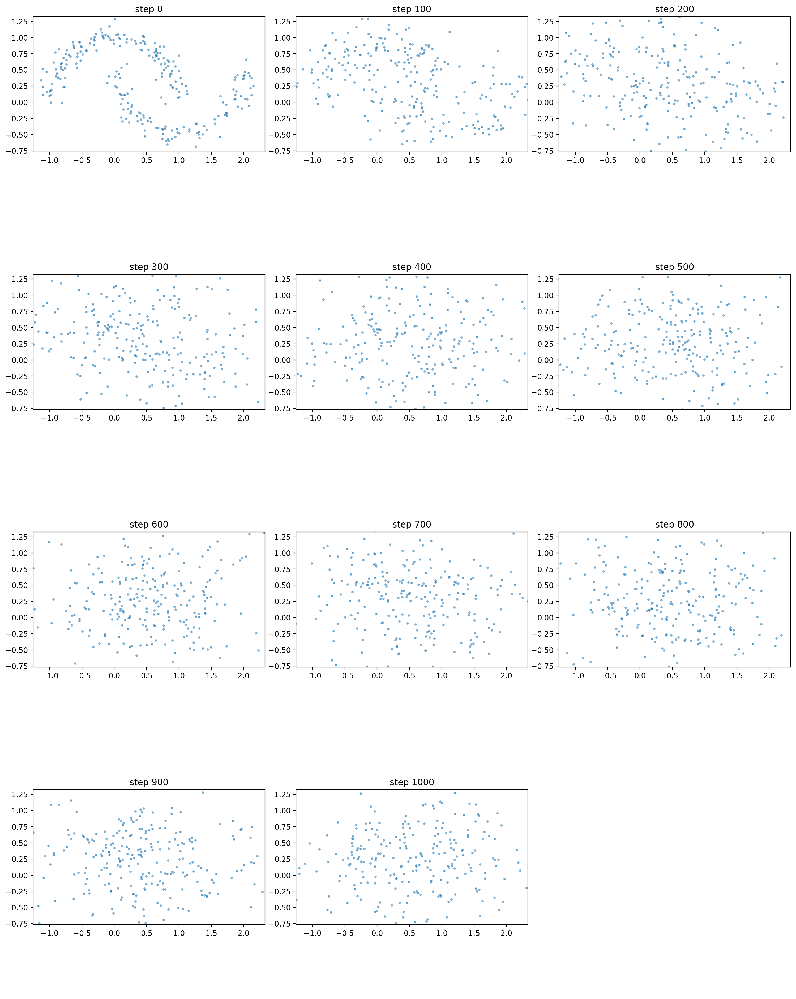

In [ ]:
x0, y0 = next(iter(loader))
x0 = x0[:1000].to(device)
xt, x_inter = diffusion.q_sample_loop(x0, log_step=100)

num_plots = len(x_inter)
ncols = 3
nrows = (num_plots + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = axes.flatten()

xlim = (dataset.X[:, 0].min().item(), dataset.X[:, 0].max().item())
ylim = (dataset.X[:, 1].min().item(), dataset.X[:, 1].max().item())

for idx, (ax, x_t) in enumerate(zip(axes, x_inter)):
    x_plot = x_t.detach().cpu() * dataset.std + dataset.mean
    ax.scatter(x_plot[:, 0], x_plot[:, 1], s=5, alpha=0.5)
    ax.set_title(f"step {min(idx * 100, diffusion.T)}")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")

for ax in axes[num_plots:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Now, show more steps between 0 and 200 to get a fine-grained understanding of what is happening with the $x_t$.

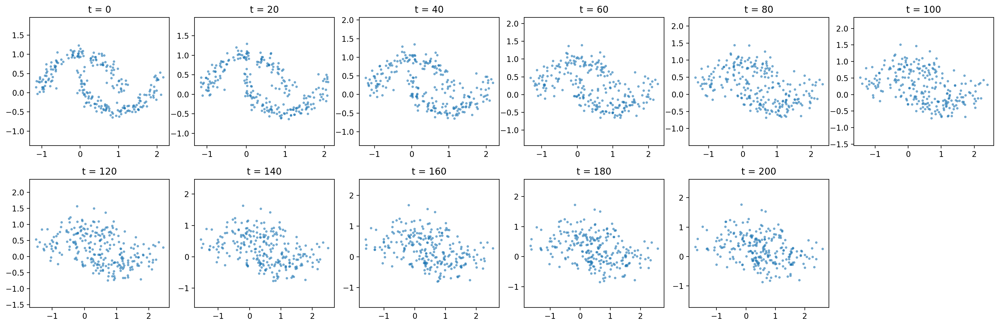

In [ ]:
timesteps_to_show = list(range(0, 201, 20))
noise = torch.randn_like(x0)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
axes = axes.flatten()

for ax, t_value in zip(axes, timesteps_to_show):
    t = torch.full((x0.shape[0],), t_value, device=device, dtype=torch.long)
    x_t = diffusion.q_sample(x0, t, noise=noise)
    x_plot = x_t.detach().cpu() * dataset.std + dataset.mean
    ax.scatter(x_plot[:, 0], x_plot[:, 1], s=5, alpha=0.5)
    ax.set_title(f"t = {t_value}")
    ax.axis("equal")

for ax in axes[len(timesteps_to_show):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


What can you say about the connection between $t$ and $x_t$? How the similarity between moons and $x_t$ changes with $t$?

чем больше t тем больше у нас шума и тем хуже видны луны. то есть у нас монотонно уменьшается информация и все шумируется в обычный гауссовский шум. при t до 60 луны отчетливо видны, но их границы размываются и сами они больше разбрасываются вокруг себя. при t до 40 луны сливаются друг с другом и становятся толще. При больших t у нас уже приближенный гауссовский шум без особых признаков лун.

### Task 10 [0.75 pts]

Now that we know that our `Diffusion` module is correct by testing it on a simple task with a simple architecture, we can move on with a more advanced architecture and a real-life problem.

We will focus on the super-resolution task, i.e., given a coarse image $c$, we want to restore its detailed version $x$.
$$
\text{DDPM}(x_{T}, c) \to x
$$

Since the images are large, we will work in the LDM setting, i.e., we will apply diffusion in the latent VAE space instead of a pixel space.

First, we need to get a dataset.

1. Download [CelebHQ](https://huggingface.co/datasets/mattymchen/celeba-hq) dataset.
2. Downscale images to $128 \times 128$ **using `bicubic` method**. This will be our target $x$.
3. Downscale images further to $16 \times 16$  **using `bicubic` method** and then upscale this low-resolution image back to $128 \times 128$  **using `bicubic` method**. This is our coarse conditional image $c$.
4. Use VAE from Stable Diffusion (the one we used in the First Part of the Homework) and encode $x$ and $c$ into the latent space. Use $\mu(x)$ without sampling for deterministic results.

**Hint:** you can do it using HF `.map` batched operation to save RAM.

**Hint:** you may want to save the dataset on disk or upload it to your HF account to avoid rerunning this step every time you re-run the session.

**Note** even though VAE is pretrained for even higher resolution images, it still works well for our $128 \times 128$ case.

In [ ]:
import torch
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, PNDMScheduler

device = "cuda" if torch.cuda.is_available() else "cpu"

vae = AutoencoderKL.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="vae").to(device)
vae.eval()

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recomme

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

In [ ]:
from torchvision.transforms import InterpolationMode
from torchvision.transforms.functional import resize, to_tensor

def make_transformed_images(pil_image):
    x = resize(pil_image, [128, 128], interpolation=InterpolationMode.BICUBIC)
    c = resize(x, [16, 16], interpolation=InterpolationMode.BICUBIC)
    c = resize(c, [128, 128], interpolation=InterpolationMode.BICUBIC)

    x = to_tensor(x) * 2.0 - 1.0
    c = to_tensor(c) * 2.0 - 1.0
    return x, c



In [ ]:
dtype = torch.float32
@torch.no_grad()
def encode_batch(images):
    latents = (vae.encode(images.to(device=device, dtype=dtype)).latent_dist.mean * vae.config.scaling_factor)
    return latents.detach().cpu().to(dtype)


In [ ]:
def preprocess_batch(batch):
    x_list = []
    c_list = []
    for img in batch["image"]:
        x, c = make_transformed_images(img.convert("RGB"))
        x_list.append(x)
        c_list.append(c)

    return {
        "x_latents": list(encode_batch(torch.stack(x_list)).numpy()),
        "c_latents": list(encode_batch(torch.stack(c_list)).numpy()),
    }

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from datasets import load_dataset, load_from_disk
import os

raw_ds = load_dataset("mattymchen/celeba-hq", split="train")

latent_ds = raw_ds.map(
    preprocess_batch,
    batched=True,
    batch_size=32,
    remove_columns=raw_ds.column_names,
    desc="Encoding CelebA-HQ to latents",
)

save_path = "/content/drive/MyDrive/celebahq_latents_128"
latent_ds.save_to_disk(save_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Encoding CelebA-HQ to latents:   0%|          | 0/28000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/28000 [00:00<?, ? examples/s]

Create a `PyTorch` dataset that will return the target and condition images in the latent space. Create a DataLoader. Use batch size set to $32$

In [ ]:
from datasets import load_from_disk
from google.colab import drive
drive.mount('/content/drive')

latent_ds = load_from_disk("/content/drive/MyDrive/celebahq_latents_128")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
latent_ds.features

{'x_latents': List(List(List(Value('float32')))),
 'c_latents': List(List(List(Value('float32'))))}

In [ ]:
from torch.utils.data import Dataset, DataLoader

class DictTensorDataset(Dataset):
    def __init__(self, x, c):
        self.x_latents = x
        self.c_latents = c

    def __len__(self):
        return len(self.x_latents)

    def __getitem__(self, idx):
        return {
            "x_item": self.x_latents[idx],
            "z_item": self.c_latents[idx]
        }

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

latent_splits = latent_ds.train_test_split(test_size=0.1, seed=57)

train_ds = latent_splits["train"]
val_ds = latent_splits["test"]

train_dict = train_ds.with_format('torch')[:]
val_dict = val_ds.with_format('torch')[:]

train_dataset = DictTensorDataset(train_dict['x_latents'], train_dict['c_latents'])
val_dataset = DictTensorDataset(val_dict['x_latents'], val_dict['c_latents'])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, num_workers=16, shuffle=False)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
print(len(train_dataset))
print(train_dataset[0]["x_item"].shape)
print(train_dataset[0]["z_item"].shape)

25200
torch.Size([4, 16, 16])
torch.Size([4, 16, 16])


### Task 11 [1 pts]

For estimating noise, we will use the UNet architecture with the following setup:

1. Each level consists of

    * Two ResBlocks with 2 convolutions of $3\times 3$ size, BatchNorm, and GELU.
    * Average Pooling for Downsampling / ConvTranspose for Upsampling

2. Three downsample/upsample blocks with the Self-Attention in the last low-level blocks.

3. 1 Mid Block with ResBlock + Self-Attetion + ResBlock.

4. Each level gets twice as more chanells when going down, going up is symmetric.

5. Time conditioning is applied by projecting a temporal embedding into each of the ResBlocks' spaces and adding it between two convolutions.


While there are plenty of ways how conditioning can be designed for UNet, we will use the most simple approach and concatenate $z_t$ and $c$ across channels in the UNet input.

**Note:** You must write the UNet from scratch yourself. You are only allowed to use simple `nn` layers, such as Linear, Convolution (+ Transposed), Activation layers, Embedding, Normalization Layers, and Self-Attention, `nn.Sequential` or `nn.ModuleList`.

In [ ]:
import torch
import torch.nn as nn


class Attention2d(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        x_seq = x.flatten(2).transpose(1, 2)
        out, _ = self.attn(x_seq, x_seq, x_seq)
        out = out.transpose(1, 2).reshape(b, c, h, w)
        return x + out


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.BatchNorm2d(in_ch)
        self.act1 = nn.GELU()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)

        self.t_proj = nn.Linear(t_dim, out_ch)

        self.norm2 = nn.BatchNorm2d(out_ch)
        self.act2 = nn.GELU()
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.skip = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x, t):
        h = self.conv1(self.act1(self.norm1(x)))
        h = h + self.t_proj(t)[:, :, None, None]
        h = self.conv2(self.act2(self.norm2(h)))
        return h + self.skip(x)


class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim, attn=False):
        super().__init__()
        self.res1 = ResBlock(in_ch, out_ch, t_dim)
        self.res2 = ResBlock(out_ch, out_ch, t_dim)
        self.attn = Attention2d(out_ch) if attn else nn.Identity()
        self.pool = nn.AvgPool2d(2)

    def forward(self, x, t):
        x = self.res1(x, t)
        x = self.res2(x, t)
        x = self.attn(x)
        skip = x
        x = self.pool(x)
        return x, skip


class MidBlock(nn.Module):
    def __init__(self, ch, t_dim):
        super().__init__()
        self.res1 = ResBlock(ch, ch, t_dim)
        self.attn = Attention2d(ch)
        self.res2 = ResBlock(ch, ch, t_dim)

    def forward(self, x, t):
        x = self.res1(x, t)
        x = self.attn(x)
        x = self.res2(x, t)
        return x


class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, t_dim, attn=False):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, 2)
        self.res1 = ResBlock(out_ch + skip_ch, out_ch, t_dim)
        self.res2 = ResBlock(out_ch, out_ch, t_dim)
        self.attn = Attention2d(out_ch) if attn else nn.Identity()

    def forward(self, x, skip, t):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        x = self.res1(x, t)
        x = self.res2(x, t)
        x = self.attn(x)
        return x


class SimpleCondUNet(nn.Module):
    def __init__(self, x_ch=4, cond_ch=4, base=64, T=1000):
        super().__init__()
        self.t_emb = nn.Embedding(T, base)
        self.in_conv = nn.Conv2d(x_ch + cond_ch, base, 3, padding=1)

        self.down1 = DownBlock(base, base, base, False)
        self.down2 = DownBlock(base, 2 * base, base, False)
        self.down3 = DownBlock(2 * base, 4 * base, base, True)

        self.mid = MidBlock(4 * base, base)

        self.up3 = UpBlock(4 * base, 4 * base, 2 * base, base, True)
        self.up2 = UpBlock(2 * base, 2 * base, base, base, False)
        self.up1 = UpBlock(base, base, base, base, False)

        self.out_conv = nn.Conv2d(base, x_ch, 3, padding=1)

    def forward(self, x, t, cond):
        t = self.t_emb(t)

        x = self.in_conv(torch.cat([x, cond], dim=1))

        x, s1 = self.down1(x, t)
        x, s2 = self.down2(x, t)
        x, s3 = self.down3(x, t)

        x = self.mid(x, t)

        x = self.up3(x, s3, t)
        x = self.up2(x, s2, t)
        x = self.up1(x, s1, t)

        return self.out_conv(x)

### Task 12 [0.75 pts]

A common metric for evaluating generative models is [FID](https://en.wikipedia.org/wiki/Fr%C3%A9chet_inception_distance), which compares the distributions of the real and generated data. However, when we know the matching between real and generated samples, we can use more interpretable and informative metrics.

In super-resolution, we know the ground-truth high-resolution image $x$ for each condition $c$. Therefore, we can compare directly $x$ with the generated $\hat{x}$. We care about three scores:

* Pixel Similarity

* Structural Similarity

* Perceptual Similarity

PSNR, SSIM, and LPIPS are the metrics that give us these three measurements.

Write the code that will run your diffusion model over the validation set and compute these metrics.

**Note**: you can use `torchmetrics` and `lpips` libraries. For LPIPS, use the `alexnet` (default) variant.

In [ ]:
@torch.no_grad()
def decode_latents(z):
    x = vae.decode(z / vae.config.scaling_factor, return_dict=False)[0]
    x = (x / 2 + 0.5).clamp(0, 1)
    return x

In [ ]:
import matplotlib.pyplot as plt
@torch.no_grad()
def log_images(diffusion, batch, exp, epoch):
    diffusion.eval()

    x = batch["x_item"].to(device)
    y = batch["z_item"].to(device)

    with torch.amp.autocast("cuda"):
      pred, _ = diffusion.sample(x.size(0), y=y)

    x = decode_latents(x).cpu()
    y = decode_latents(y).cpu()
    pred = decode_latents(pred).cpu()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(y[0].permute(1, 2, 0))
    axes[0].set_title("cond")

    axes[1].imshow(pred[0].permute(1, 2, 0))
    axes[1].set_title("pred")

    axes[2].imshow(x[0].permute(1, 2, 0))
    axes[2].set_title("target")

    for ax in axes:
        ax.axis("off")

    exp.log_figure(figure_name=f"val_images_epoch_{epoch:03d}", figure=fig, step=epoch)
    plt.close(fig)
    plt.close(fig)

In [ ]:
pip install lpips

In [ ]:
pip install torchmetrics

In [ ]:
import lpips
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure

psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
lpips_metric = lpips.LPIPS(net="alex").to(device)

from tqdm.auto import tqdm

@torch.no_grad()
def evaluate(diffusion, loader, exp=None, ep=None, max_batches=None):
    diffusion.eval()

    psnr = ssim = lp = n = 0

    for i, batch in enumerate(tqdm(loader, leave=False)):
        if max_batches and i >= max_batches:
            break

        x = batch["x_item"].to(device)
        y = batch["z_item"].to(device)

        with torch.amp.autocast("cuda"):
          pred, _ = diffusion.sample(x.size(0), y=y)

        bs = x.size(0)
        x_img, pred_img = decode_latents(x), decode_latents(pred)

        psnr += psnr_metric(pred_img, x_img).item() * bs
        ssim += ssim_metric(pred_img, x_img).item() * bs
        lp += lpips_metric(pred_img * 2 - 1, x_img * 2 - 1).mean().item() * bs
        n += bs

        if exp and ep is not None and i == 0:
            log_images(diffusion, batch, exp, ep)

    if exp and ep is not None:
        exp.log_metrics({
            "val_psnr": psnr / n,
            "val_ssim": ssim / n,
            "val_lpips": lp / n,
        }, step=ep)

    return {
        "val_psnr": psnr / n,
        "val_ssim": ssim / n,
        "val_lpips": lp / n,
    }

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth


### Task 13 [1.5 pts]

Now create the training script. Log metrics and sample some images each epoch. In total, run these three experiments:

1. **One-Batch Test**. This is another technique for validating your pipeline before moving on with the full training. Given a fixed batch $B$, you train your model only on this $B$ for many steps **and evaluate also on the same batch $B$**. If your pipeline is correct, the model should overfit on this batch, i.e., achieve good metrics, low loss, and nice samples. Depending on the task, the loss and metrics can achieve the perfect scores; but for diffusion, we will primary look at the generated samples and how well they match the target image. For this experiment, use $T=50$. **Important**: passing one-batch test *does not gurantee* that your pipeline is fully correct, but not passing it means you have a bug somewhere.

2. Run full dataset training with $T=100$ diffusion steps in the noise schedule.

3. The same as 2, but with $T=1000$.

**Note**: during training, you can evaluate only on a subset.

**Note**: to get the full grade, your $T=100$ model must be able to achieve $\text{LPIPS} < 20.5$

In [ ]:
pip install comet_ml

In [ ]:
import comet_ml
comet_ml.login()

In [ ]:
from comet_ml import Experiment
from tqdm.auto import tqdm
import torch
from torch.cuda.amp import autocast, GradScaler

def train(diffusion, train_loader, val_loader, optimizer, epochs, save_path, log_step=10, exp_name="1"):
    experiment = Experiment(project_name="hw3-diffusion")
    experiment.set_name(exp_name)

    scaler = torch.amp.GradScaler("cuda")
    best_lpips = float("inf")

    for epoch in tqdm(range(epochs), desc="Training"):
        diffusion.train()
        epoch_loss = 0.0
        num_steps = len(train_loader)
        pbar = tqdm(train_loader, leave=False, desc=f"Epoch {epoch + 1}")

        for batch in pbar:
            x = batch["x_item"].to(device)
            cond = batch["z_item"].to(device)

            optimizer.zero_grad()

            with torch.amp.autocast("cuda"):
                loss = diffusion.compute_loss(x, cond)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            epoch_loss += loss.item()

        epoch_loss /= num_steps
        experiment.log_metric("train_epoch_loss", epoch_loss, step=epoch)

        if (epoch + 1) % log_step == 0:
            val_metrics = evaluate(diffusion, val_loader, exp=experiment, ep=epoch, max_batches=10)

            if val_metrics["val_lpips"] < best_lpips:
                best_lpips = val_metrics["val_lpips"]
                torch.save({
                    "model": diffusion.state_dict(),
                    "optimizer": optimizer.state_dict(),
                }, save_path)

    val_metrics = evaluate(diffusion, val_loader, exp=experiment, ep=epochs, max_batches=10)
    print(
        f"train_loss={epoch_loss:.4f}, "
        f"val_psnr={val_metrics['val_psnr']:.4f}, "
        f"val_ssim={val_metrics['val_ssim']:.4f}, "
        f"val_lpips={val_metrics['val_lpips']:.4f}"
    )
    experiment.end()

In [ ]:
batch = next(iter(train_loader))
one_batch_loader = [{
    "x_item": batch["x_item"].to(device),
    "z_item": batch["z_item"].to(device)
}]

In [ ]:
model_test = SimpleCondUNet(
    x_ch=4,
    cond_ch=4,
    base=64,
    T=50,
).to(device)

diffusion_test = ConditionalGaussianDiffusion(
    model=model_test,
    image_shape=(4, 16, 16),
    timesteps=50,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer_test = torch.optim.AdamW(model_test.parameters(), lr=1e-4)


In [ ]:
train(
    diffusion_test,
    one_batch_loader,
    one_batch_loader,
    optimizer_test,
    epochs=1000,
    save_path="/content/drive/MyDrive/hw3/one_batch.pt",
    log_step=50,
    exp_name="atent_diffusion_sr_one_batch"
)

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : atent_diffusion_sr_one_batch
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/d905fdd40ee54bdd808d9fa3a0669ee9
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [60] : (0.8220897912979126, 1.1013717651367188)
COMET INFO:     val_lpips [5]         : (0.6501069068908691, 0.6610087156295776)
COMET INFO:     val_psnr [5]          : (6.406321048736572, 7.0387368202209

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_1556/1240937957.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 2:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Epoch 72:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 73:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 74:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 75:   0%|          | 0/1 [00:00<?, ?it/s]

Тут не прогрузилась ячейка, но в комет все прикрепила и можно посмотреть по ссылке.

In [ ]:
model_t_100 = SimpleCondUNet(
    x_ch=4,
    cond_ch=4,
    base=64,
    T=100,
).to(device)

diffusion_t_100 = ConditionalGaussianDiffusion(
    model=model_t_100,
    image_shape=(4, 16, 16),
    timesteps=100,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer_test = torch.optim.Adam(model_t_100.parameters(), lr=1e-4)

train(
    diffusion_t_100,
    train_loader,
    val_loader,
    optimizer_test,
    epochs=100,
    save_path="/content/drive/MyDrive/hw3/diff_t_100_1.pt",
    log_step=10,
    exp_name="atent_diffusion_sr_100"
)


COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: torch, sklearn.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nrgpmo/hw3-diffusion/1aa79d5d781f449a80ad5c845813bcda



Training:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/788 [00:00<?, ?it/s]

COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


Epoch 2:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/788 [00:00<?, ?it/s]

... (227 outputs left out)

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

train_loss=0.3027, val_psnr=18.9718, val_ssim=0.5075, val_lpips=0.1790


COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : atent_diffusion_sr_100
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/1aa79d5d781f449a80ad5c845813bcda
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [100] : (0.3026902776041309, 0.5490540924864977)
COMET INFO:     val_lpips [11]         : (0.1780723139643669, 0.25137644112110136)
COMET INFO:     val_psnr [11]          : (18.28681163787842, 18.97175064086914)
COMET INFO:     val_ssim [11]          : (0.4439258694648743, 0.5075365662574768)
COMET INFO:   Others:
COMET INF

In [ ]:
model_t_1000 = SimpleCondUNet(
    x_ch=4,
    cond_ch=4,
    base=64,
    T=1000,
).to(device)

diffusion_t_1000 = ConditionalGaussianDiffusion(
    model=model_t_1000,
    image_shape=(4, 16, 16),
    timesteps=1000,
    beta_schedule="linear",
    device=device,
).to(device)

optimizer_test = torch.optim.Adam(model_t_1000.parameters(), lr=1e-4)

train(
    diffusion_t_1000,
    train_loader,
    val_loader,
    optimizer_test,
    epochs=100,
    save_path="/content/drive/MyDrive/hw3/diff_t_1000.pt",
    log_step=10,
    exp_name="atent_diffusion_sr_1000"
)


COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: torch, sklearn.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nrgpmo/hw3-diffusion/f6f31f28e30e458b80f006d20f571842



Training:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/788 [00:00<?, ?it/s]

COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


Epoch 2:   0%|          | 0/788 [00:00<?, ?it/s]

Epoch 3:   0%|          | 0/788 [00:00<?, ?it/s]

... (228 outputs left out)

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

train_loss=0.1126, val_psnr=19.7420, val_ssim=0.5591, val_lpips=0.1542


COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : atent_diffusion_sr_1000
COMET INFO:     url                   : https://www.comet.com/nrgpmo/hw3-diffusion/f6f31f28e30e458b80f006d20f571842
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     train_epoch_loss [100] : (0.110660441555461, 0.2847025256301395)
COMET INFO:     val_lpips [11]         : (0.15415294617414474, 0.22409117221832275)
COMET INFO:     val_psnr [11]          : (18.85969181060791, 19.966778182983397)
COMET INFO:     val_ssim [11]          : (0.48424779772758486, 0.5677946925163269)
COMET INFO:   Others:
COMET 

Evaluate the performance of model with $T=100$ and with $T=1000$ on the full validation dataset. Compare with the metrics for the `bicubic` baseline (the $c$ itself).

In [ ]:
@torch.no_grad()
def evaluate_baseline(loader):
    psnr = ssim = lp = n = 0

    for batch in tqdm(loader, leave=False):
        x = batch["x_item"].to(device)
        y = batch["z_item"].to(device)

        x_img = decode_latents(x)
        pred_img = decode_latents(y)

        bs = x.size(0)
        psnr += psnr_metric(pred_img, x_img).item() * bs
        ssim += ssim_metric(pred_img, x_img).item() * bs
        lp += lpips_metric(pred_img * 2 - 1, x_img * 2 - 1).mean().item() * bs
        n += bs

    return {
        "val_psnr": psnr / n,
        "val_ssim": ssim / n,
        "val_lpips": lp / n,
    }

In [ ]:
metrics_base = evaluate_baseline(val_loader)
print("Bicubic:", metrics_base)

  0%|          | 0/88 [00:00<?, ?it/s]

Bicubic: {'val_psnr': 21.481810531616212, 'val_ssim': 0.6051974838120596, 'val_lpips': 0.5271413912091937}


In [ ]:
metrics_100 = evaluate(diffusion_t_100, val_loader, max_batches=None)
print("T=100:", metrics_100)

  0%|          | 0/88 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

... (80 outputs left out)

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/100 [00:00<?, ?it/s]

T=100: {'val_psnr': 18.95054272242955, 'val_ssim': 0.5027736956732614, 'val_lpips': 0.1805669299193791}


In [17]:
metrics_1000 = evaluate(diffusion_t_1000, val_loader, max_batches=None)
print("T=1000:", metrics_1000)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  0%|          | 0/88 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

... (81 outputs left out)

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

Reverse diffusion:   0%|          | 0/1000 [00:00<?, ?it/s]

T=1000: {'val_psnr': 19.721385454450335, 'val_ssim': 0.5550726849692208, 'val_lpips': 0.15486337968281338}


У bicubic получились лучше psnr и ssim, но хуже lpips, чем у диффузии. Это связано с тем, что диффузия старается сделать картинку глобально похожей, структурно, она минимизирует (вообще говоря предсказывая шум) расстояние в латентном пространстве, а не попиксельное. Psnr вообще зависит от того как конкретные пиксели отличаются, а ssim смотрит по окнам тоже разницу функций от пикселей. То есть это все пиксельные метрики, задачу приближения которых диффузия не решает, поэтому на них и становится хуже. А вот lpips это модель обученная сравнивать картинки тем, что она их преобозовывала. Соответственно ее признаки для похожих картинок должны быть похожи. То есть это не пиксельное сравнение, а предоубченное на глобальную похожесть и это примерно та же задача, что и диффузии.

при 1000 все метрики получились лучше. по пиксельно особо нет разницы, но мы уже и говорили что это не задача диффузии. Стало лучше ssim, он все-таки смотрит какую-то общую структуру изображения по окнам. и главное lpips стало лучше. Потому что чем больше t, тем на более мелкие задачи мы делим для нашей модели, там более мелкий и простой шум, который проще предсказывать. Проблема в том, что скорость семплирования линейно растет при увеличении шагов. Еще теоретически когда мы сильно сильно увеличиваем шаги, у нас на каждом шагу накапливаются ошибки, не смотря на очень простые задачи, и эти ошибки большие по сравнению с задачами из-за их размера и в итоге что-то не то получается. То есть до бесконечности нельзя шаги увеличивать.

What can you say about PSNR/SSIM/LPIPS metrics for bicubic and diffusion? Are the results surprising? Explain the differences you see and if the result is reasonable. Also, what difference do you see between $T=100$ and $T=1000$? Why is it like that? What are the pros and cons of changing $T$?

**Hint** look at the definition of the metrics.

**YOUR RESPONSE HERE:**

### Bonus [1.5 pts]

Implement deterministic [DDIM](https://arxiv.org/abs/2010.02502) version of inference for your model. We discussed the core idea in the first part of the notebook.

**Note** DDIM is a sampling inference technique, you do not need to retrain the model.

In [ ]:
model_t_100_n = SimpleCondUNet(
    x_ch=4,
    cond_ch=4,
    base=64,
    T=100,
).to(device)

diffusion_t_100_n = ConditionalGaussianDiffusion(
    model=model_t_100_n,
    image_shape=(4, 16, 16),
    timesteps=100,
    beta_schedule="linear",
    device=device,
).to(device)


In [ ]:
checkpoint = torch.load("/content/drive/MyDrive/hw3/diff_t_100_1.pt", map_location=device)

diffusion_t_100_n.load_state_dict(checkpoint["model"])

<All keys matched successfully>

In [ ]:
@torch.no_grad()
def ddim_sample(self, xt, t, y=None):
    eps = self.model(xt, t, y)
    alpha_t = self.extract(self.alphas_cumprod, t, xt.shape)
    alpha_prev = self.extract(self.alphas_cumprod, torch.clamp(t - 1, min=0), xt.shape)
    x0 = (xt - torch.sqrt(1 - alpha_t) * eps) / torch.sqrt(alpha_t)
    if t[0] == 0:
        return x0
    x_prev = torch.sqrt(alpha_prev) * x0 + torch.sqrt(1 - alpha_prev) * eps
    return x_prev

In [ ]:
@torch.no_grad()
def ddim_sample_all(self, n, log_step=100, y=None):
    x_inter = []
    xt = torch.randn(n, *self.image_shape, device=self.device)

    for i in tqdm(reversed(range(self.T)), total=self.T, desc="Reverse diffusion", leave=False):
        xt = self.ddim_sample(xt, torch.full((n,), i, device=self.device, dtype=torch.long), y)
        if (self.T - i - 1) % log_step == 0:
            x_inter.append(xt)

    x_inter.append(xt)
    return xt, x_inter  # typically clamp/convert to [0,1] outside

Compare DDIM with different number of steps $N$ vs DDPM in terms of generation quality and speed. Similarly to Classifier-Free Guidance experiments, we expect you to come up with a meaningful and informative experiment fully exploring the trade-off between DDIM and DDPM. Think about the experiment design and presentation options for your results and analysis. We will evaluate both the experimental setup and the analysis.

**Hint** recall how we designed experiments during the course, what concepts we introduced, and what advice we gave.

**YOUR ANALYSIS OF THE EXPERIMENTS HERE:**